In [1]:
!nvidia-smi --query-gpu=index,name,memory.total,memory.used --format=csv

index, name, memory.total [MiB], memory.used [MiB]
0, Tesla T4, 15360 MiB, 0 MiB
1, Tesla T4, 15360 MiB, 0 MiB


install ollama

Installs zstd, the tool that unpacks Ollama’s compressed download. -qq and > /dev/null hide the long output.

Downloads Ollama’s official install script (curl) and runs it (| sh).

Installs the Python package ollama, which our code will use to talk to Ollama.

In [2]:
!apt-get update -qq && apt-get install -y -qq zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip install -q ollama

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%.3%#################                                          45.2%#############                                      50.6%##################                         69.3%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


## 3. Start the Ollama server on GPU 0 only

Kaggle has no systemd, so Ollama does not start by itself. We start it in the background.

**Environment variables** are settings Ollama reads once, when it starts. Changing them later has no effect until Ollama is restarted.

| Setting | Value | Meaning |
|---|---|---|
| `CUDA_VISIBLE_DEVICES` | `0` | Ollama sees only GPU 0; GPU 1 stays unused |
| `OLLAMA_CONTEXT_LENGTH` | `8192` | Most tokens the model reads per question; smaller uses less GPU memory |
| `OLLAMA_KEEP_ALIVE` | `-1` | Keep the model on the GPU forever (default unloads it after 5 idle minutes), work on background |
| `OLLAMA_HOST` | `127.0.0.1:11434` | Address Ollama listens on: this same machine, port 11434 |

The loop at the end asks Ollama "are you ready?" once per second, because it needs a moment to start.

In [4]:
import os, subprocess, time, requests

# Settings Ollama reads when it starts
env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"]  = "0"
env["OLLAMA_CONTEXT_LENGTH"] = "8192"
env["OLLAMA_KEEP_ALIVE"]     = "-1"
env["OLLAMA_HOST"]           = "127.0.0.1:11434"

# Start "ollama serve" in the background; its messages go to a log file
log_file = open("/kaggle/working/ollama.log", "w")
ollama_process = subprocess.Popen(["ollama", "serve"], env=env,
                                  stdout=log_file, stderr=subprocess.STDOUT)

# Ask Ollama "are you ready?" once per second, up to 30 times
for _ in range(30):
    try:
        reply = requests.get("http://127.0.0.1:11434/api/version", timeout=1)
        print("Ollama is running, version", reply.json()["version"])
        break
    except requests.exceptions.ConnectionError:
        time.sleep(1)
else:
    print("Ollama did not start. Look at /kaggle/working/ollama.log")

Ollama is running, version 0.40.10


## 4. Download the model

`qwen3.5:9b` is about 6.6 GB (4-bit). It fits on one T4 (15 GB) with room left for the images.
The download shows progress every 10 %.

Which file: qwen3.5:9b is about 6.6 GB. It’s quantized to 4-bit, meaning each number in the model is stored with 4 bits instead of 16. That makes the file about 4 times smaller, at a small cost in quality. 6.6 GB fits easily in GPU 0’s 15 GB, which leaves room for the frames

In [5]:
import ollama

MODEL = "qwen3.5:9b"

last_shown = -10
for update in ollama.pull(MODEL, stream=True):
    total, done = update.get("total"), update.get("completed")
    if total and done:
        percent = int(100 * done / total)
        if percent >= last_shown + 10:
            print(f"{update['status']}: {percent}%")
            last_shown = percent
    elif update.get("status") == "success":
        print("Download finished")

pulling f836f08f9211: 0%
pulling f836f08f9211: 12%
pulling f836f08f9211: 25%
pulling f836f08f9211: 36%
pulling f836f08f9211: 48%
pulling f836f08f9211: 60%
pulling f836f08f9211: 73%
pulling f836f08f9211: 83%
pulling f836f08f9211: 93%
Download finished


## 5. First questions (warm-up)

The first call loads the model from disk onto GPU 0, so it is slow. Later calls are fast.
`think=False`: Qwen3.5 is a "thinking" model. By default it writes long hidden reasoning before answering,
which can take minutes. `think=False` makes it answer directly.

ask is a small helper we’ll reuse. It builds one message, a Python dictionary with role (who is speaking: "user" = us) and content (the text).

images is optional. We use it in the next step.

time.time() reads the clock in seconds. The clock after the call minus the clock before it is how long the call took.

f"{seconds:.1f}" prints the number with one decimal place, for example 23.4

Ollama wants an image file, meaning compressed bytes like a JPEG or PNG.

or Bytes of an encoded image , the contents of a .jpg file, as Python bytes

In [6]:
def ask(question, images=None):
    """Send one question (with optional images) to the model. Returns (answer, seconds)."""
    message = {"role": "user", "content": question}
    if images:
        message["images"] = images          # list of image file paths or image bytes

    start = time.time()
    response = ollama.chat(model=MODEL, messages=[message], think=False)
    seconds = time.time() - start
    return response["message"]["content"], seconds

# Call 1: loads the model onto the GPU (slow)
answer, seconds = ask("Say hello in five words.")
print(f"Call 1: {seconds:.1f} s -> {answer}")

# Call 2: same question again (model already on the GPU, so fast)
answer, seconds = ask("Say hello in five words.")
print(f"Call 2: {seconds:.1f} s -> {answer}")

Call 1: 105.9 s -> Hello there, friend.
Call 2: 0.3 s -> Hello, nice to meet you!


ollama ps lists the loaded models. The PROCESSOR column must say 100% GPU. If it says something like 30%/70% CPU/GPU, part of the model is on the slow CPU.

nvidia-smi should show GPU 0 using several GB and GPU 1 still at 0 MiB. That proves only one GPU is in use.

Column	Value	Meaning

NAME	qwen3.5:9b	the model we downloaded

SIZE	5.9 GB	how much memory it takes when loaded

PROCESSOR	100% GPU	the whole model is on the GPU, none on the slow CPU (this is what we wanted)

CONTEXT	8192	the token limit we set with OLLAMA_CONTEXT_LENGTH

RUNNER	llamacpp	the engine Ollama uses inside to run the model

UNTIL	Forever	our OLLAMA_KEEP_ALIVE=-1: it will never unload

(

In [7]:
!ollama ps
!nvidia-smi --query-gpu=index,memory.used,memory.total --format=csv

]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen3.5:9b    56671c2ab938    5.9 GB    100% GPU     8192       llamacpp    Forever    
index, memory.used [MiB], memory.total [MiB]
0, 6601 MiB, 15360 MiB
1, 0 MiB, 15360 MiB


## 6. First image question

We draw a fake camera frame as a matrix (OpenCV), compress it to JPEG bytes, and ask the model about it.
This checks that the vision part works before we use real video.

np.full((288, 512, 3), 45) creates the matrix with every number set to 45 (dark grey). 512 × 288 is the same shape as a phone video (16:9), just small.

OpenCV colours are in the order B, G, R (blue, green, red), not R, G, B. So (200, 90, 30) is mostly blue and (30, 30, 200) is mostly red.

In cv2.rectangle(frame, (x1, y1), (x2, y2), colour, -1), the two points are opposite corners, and -1 means “fill it in”.

display(...) shows the JPEG under the cell, so you can compare what you see with what the model says.

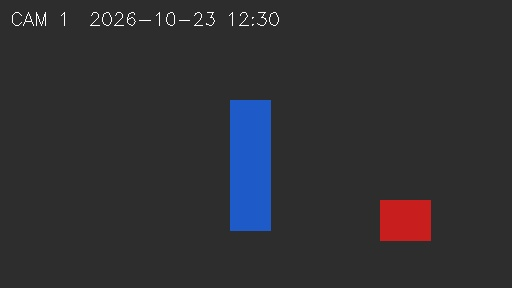

7.1 s -> A static security camera feed shows a dark background with a blue vertical rectangle and a red square to its right. The on-screen text reads "CAM 1 2026-10-23 12:30".


In [8]:
import cv2, numpy as np
from IPython.display import Image, display

# 1. Draw a fake camera frame: a matrix of 288 rows x 512 columns x 3 colours (Blue, Green, Red)
frame = np.full((288, 512, 3), 45, dtype=np.uint8)                       # dark grey background
cv2.putText(frame, "CAM 1  2026-10-23 12:30", (10, 25),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)          # white text at the top
cv2.rectangle(frame, (230, 100), (270, 230), (200, 90, 30), -1)         # a blue "person"
cv2.rectangle(frame, (380, 200), (430, 240), (30, 30, 200), -1)         # a red box on the floor

# 2. Matrix -> JPEG bytes
ok, jpeg = cv2.imencode(".jpg", frame)
jpeg_bytes = jpeg.tobytes()
display(Image(data=jpeg_bytes))          # show it in the notebook

# 3. Ask the model
answer, seconds = ask("Describe this security camera frame in 2 sentences. "
                      "Then read the on-screen text exactly.", images=[jpeg_bytes])
print(f"{seconds:.1f} s -> {answer}")

What this answer shows

What the model got right:

Two coloured rectangles, a blue one and a red one.
The blue one is taller. That’s true: it’s 130 pixels tall (230 − 100) against 40 for the red one (240 − 200).
It read the text and kept it in the right order.

What it got wrong:

It read 2028 instead of 2026. That’s one wrong digit. The text is small (font scale 0.6, only about 12 pixels tall), and at that size a 6 and an 8 look similar. This is a reading (OCR) error. For the demo, keep in mind that small text like timestamps can be misread; bigger frames (852 px) help.

“Black background”: it’s actually dark grey, value 45 out of 255, which is about 18% brightness. A minor point.
It didn’t call the blue shape a “person”. That’s fair: it’s only a rectangle. Real footage will be different.

It didn’t call the blue shape a “person”. That’s fair: it’s only a rectangle. Real footage will be different.

Why 8.1 s and not 0.3 s like the text question:

The image becomes several hundred extra tokens the model must read, and the vision part (which turns pixels into tokens) runs first. The first image question may also include a one-time setup of that vision part. Run Cell 6 again: if the second time is clearly faster, part of the 8.1 s was that setup. Tell me the second time too.

## 7. Make a test video and read it back

A video is a list of frames (matrices) plus an fps number (frames per second).
We write a 6-second test clip at 15 fps (6 x 15 = 90 frames) where a blue box moves from left to right,
then read it back and count the frames.

In [9]:
CLIP = "/kaggle/working/test_clip.mp4"
FPS = 15
SECONDS = 6

# 1. Write the video, one frame (matrix) at a time
writer = cv2.VideoWriter(CLIP, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (512, 288))
for k in range(FPS * SECONDS):                        # k = 0, 1, 2, ..., 89
    frame = np.full((288, 512, 3), 45, dtype=np.uint8)
    x = 20 + 5 * k                                     # the box moves 5 pixels right each frame
    cv2.rectangle(frame, (x, 100), (x + 40, 230), (200, 90, 30), -1)
    cv2.putText(frame, f"t = {k / FPS:.1f} s", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    writer.write(frame)
writer.release()                                       # finish and close the file

# 2. Read it back: open the file and count the frames
video = cv2.VideoCapture(CLIP)
fps = video.get(cv2.CAP_PROP_FPS)
count = 0
while video.grab():                                    # grab() moves to the next frame; False at the end
    count += 1
video.release()

print(f"fps = {fps}, frames = {count}, length = {count / fps:.1f} s")

fps = 15.0, frames = 90, length = 6.0 s


## 8. Pick N evenly spaced frames

Split the video into N equal parts and take the middle frame of each part.
Frame number of part k (k = 0, 1, ..., N-1):  (k + 0.5) * total / N, rounded down.
Example: 90 frames, N = 8 -> each part is 90 / 8 = 11.25 frames -> frames 5, 16, 28, 39, 50, 61, 73, 84.

Where the formula comes from, with 90 frames and N = 8:

Each part is 90 ÷ 8 = 11.25 frames long.

Part k starts at frame k × 11.25. Its middle is half a part further: (k + 0.5) × 11.25.

Frame numbers must be whole numbers, so we round down with int(...).

Check part 0: 0.5 × 11.25 = 5.625 → frame 5. Check part 7 (the last): 7.5 × 11.25 = 84.375 → frame 84. Both are inside 0–89.

In [10]:
def pick_indices(total, n):
    """Which frame numbers to take: the middle of each of n equal parts."""
    return [int((k + 0.5) * total / n) for k in range(n)]

for n in (1, 8, 16):
    print(n, "frames:", pick_indices(90, n))

1 frames: [45]
8 frames: [5, 16, 28, 39, 50, 61, 73, 84]
16 frames: [2, 8, 14, 19, 25, 30, 36, 42, 47, 53, 59, 64, 70, 75, 81, 87]


## 9. Sample frames from the video and ask the model

`sample_frames(path, n)` returns n evenly spaced frames as JPEG bytes, plus the time (in seconds) of each one.
We ask the same question with 1 frame and with 8 frames to see how the answer changes with more time context.

In [11]:
def sample_frames(path, n, max_side=512):
    """Return n evenly spaced frames as JPEG bytes, and the time in seconds of each frame."""
    # Pass 1: count the frames (some phone videos report a wrong count, so we count ourselves)
    video = cv2.VideoCapture(path)
    fps = video.get(cv2.CAP_PROP_FPS)
    total = 0
    while video.grab():
        total += 1
    video.release()

    wanted = pick_indices(total, n)

    # Pass 2: walk through again and keep only the wanted frames
    video = cv2.VideoCapture(path)
    frames, times = [], []
    index = 0
    while video.grab():
        if index in wanted:
            ok, frame = video.retrieve()                  # decode this frame into a matrix
            height, width = frame.shape[:2]
            scale = min(1.0, max_side / max(height, width))
            if scale < 1.0:                                # shrink only, never enlarge
                frame = cv2.resize(frame, (int(width * scale), int(height * scale)))
            frames.append(cv2.imencode(".jpg", frame)[1].tobytes())
            times.append(round(index / fps, 2))
        index += 1
    video.release()
    return frames, times


for n in (1, 8):
    frames, times = sample_frames(CLIP, n)
    question = (f"These {n} images are frames from one security camera video, in time order. "
                "Describe what happens in 1-2 sentences.")
    answer, seconds = ask(question, images=frames)
    print(f"{n} frame(s) at {times} s")
    print(f"   {seconds:.1f} s -> {answer}\n")

1 frame(s) at [3.0] s
   2.2 s -> A blue vertical bar appears on the screen at t = 3.0 s, with no prior context or motion shown in earlier frames — suggesting it may be an object entering the frame or a graphical overlay appearing suddenly in the video feed.

8 frame(s) at [0.33, 1.07, 1.87, 2.6, 3.33, 4.07, 4.87, 5.6] s
   4.7 s -> Based on the sequence of images, a blue rectangular object moves steadily from the left side of the screen towards the right. The provided timestamps indicate this motion occurs over approximately 5.6 seconds.



## 10. Where does the time go?

Ollama reports its own timing in every response (in nanoseconds; divide by 1e9 for seconds):
- reading = images + question (`prompt_eval_duration`)
- writing = producing the answer (`eval_duration`)
We also ask for a shorter answer, since writing time grows with answer length.

In [12]:
def ask_timed(question, images=None):
    """Like ask(), but also returns the time of each part."""
    message = {"role": "user", "content": question}
    if images:
        message["images"] = images
    start = time.time()
    r = ollama.chat(model=MODEL, messages=[message], think=False)
    total = time.time() - start
    timing = {
        "total_s":       round(total, 2),
        "load_s":        round(r["load_duration"] / 1e9, 2),
        "reading_s":     round(r["prompt_eval_duration"] / 1e9, 2),
        "writing_s":     round(r["eval_duration"] / 1e9, 2),
        "input_tokens":  r["prompt_eval_count"],
        "answer_tokens": r["eval_count"],
    }
    return r["message"]["content"], timing


for n in (1, 8, 16):
    frames, times = sample_frames(CLIP, n)
    question = (f"These {n} images are frames from one security camera video, in time order. "
                "Describe what happens in ONE sentence. No introduction.")
    answer, t = ask_timed(question, images=frames)
    print(f"{n:>2} frames | {t}")
    print(f"   -> {answer}\n")

 1 frames | {'total_s': 1.86, 'load_s': 0.0, 'reading_s': 0.53, 'writing_s': 1.17, 'input_tokens': 184, 'answer_tokens': 37}
   -> A blue rectangular object remains stationary at the center of the frame as the timer reads t = 3.0 s, with no motion or changes visible across this single captured moment.

 8 frames | {'total_s': 4.2, 'load_s': 0.0, 'reading_s': 3.36, 'writing_s': 0.66, 'input_tokens': 1206, 'answer_tokens': 21}
   -> A blue rectangular bar is shown moving slowly and steadily to the right across a dark background over time.

16 frames | {'total_s': 7.73, 'load_s': 0.0, 'reading_s': 6.73, 'writing_s': 0.77, 'input_tokens': 2375, 'answer_tokens': 24}
   -> A blue rectangular object moves from the left side of the screen towards the right over a period of approximately five seconds.



## 11. Results: frames vs time (qwen3.5:9b, 1x T4, frames 512x288)

| Frames | Total | Reading (images + question) | Writing (answer) | Input tokens | Answer |
|---|---|---|---|---|---|
| 1  | 2.53 s  | 0.65 s | 1.70 s | 184   | "stationary" (wrong: one frame cannot show motion) |
| 8  | 5.29 s  | 4.16 s | 0.94 s | 1,206 | moves left to right (correct) |
| 16 | 10.17 s | 8.55 s | 1.39 s | 2,375 | moves left to right (correct, same as 8) |

**Findings**
1. One 512x288 frame costs about **146 tokens**: (1,206 - 184) / 7 = 146 and (2,375 - 1,206) / 8 = 146. It depends on frame size, not content.
2. Reading costs about **0.5 s per frame** (about 3.5 ms per input token). With 8+ frames it is ~80% of the total, so it is the bottleneck.
3. Writing costs about **40 ms per answer token** (~25 tokens/s) and depends on answer length, not on frames.
4. **1 frame cannot tell direction**: the model guesses (hallucination). **8 frames** are enough for this simple motion; **16** double the time without adding information here.
5. For live mode (a new window every N seconds) processing must finish within the window: 8 frames take ~5.3 s, so use **8 frames every 8 s**, or **6 frames every 6 s**.

## 12. New plan: live pipeline on two GPUs

### What changed, and why

| Before | Now | Why |
|---|---|---|
| Phone uploads a **video**; the server cuts the frames | Phone **takes the frames itself** and sends small JPEGs | Upload drops from several MB to about 240 KB, leaving more of the 6 s for the model |
| One question per tap | **Live pipeline**: the next 6 s segment is collected while the previous one is processed | Continuous coverage, a steady rhythm of answers |
| One GPU | **One model copy per GPU**; segments alternate GPU 0 → GPU 1 → GPU 0 … | Each GPU gets 12 s per segment instead of 6, so it never falls behind |
| Clip mode cuts frames on the server | Clip mode also cuts frames **on the phone** | The server needs only **one** address, `/analyze_frames`, for both modes |

### Problems found, with their fixes

| Problem | Fix |
|---|---|
| 8 frames take ~5.3 s plus upload, about the whole 6 s window | Two GPUs alternating: 12 s per segment |
| If processing is slower than segments arrive, the delay grows forever | **Newest segment wins**: a waiting segment is replaced by the newer one |
| One frame makes the model guess (it said "stationary") | Keep the frames menu (1 / 8 / 16) to show this live |
| Small text gets misread (2028 vs 2026) | Keep the frame size menu (512 / 852 px) |
| The tunnel URL changes every time | Print a QR code; full test right before presenting |
| Kaggle or Wi-Fi can fail | Backup clips + screenshots of results |

### Delay in live mode
delay = (time left in the segment) + processing time → **6 to 12 s**, about 9 s on average.
Answers arrive every 6 s, each describing what happened 6–12 s earlier.

### Steps

| Step | What | Done when |
|---|---|---|
| 1–5 ✅ | Ollama, first questions, frame sampling, timing | Done: ~146 tokens and ~0.5 s per 512x288 frame |
| 6 | Two Ollama servers: GPU 0 on port 11434, GPU 1 on port 11435 | Both GPUs show ~6.6 GB used; both answer in ~0.3 s |
| 7 | Dispatcher: alternate GPUs, newest segment wins | Fake segments every 6 s; the delay stays steady |
| 8 | FastAPI server: `/hello`, then `/analyze_frames` | A notebook cell sends frames and gets the answer back |
| 9 | Phone page, clip mode (frames picked in the browser) | Works from the laptop browser |
| 10 | Cloudflare tunnel + QR code | Clip mode works on the phone |
| 11 | Phone page, live mode (1 frame every 0.75 s, 8 frames every 6 s) | Runs 2 minutes on the phone; delay stays 6–12 s |
| 12 | Demo-day preparation | Real timings measured, backup clips and screenshots ready |

## 13. Step 6: two Ollama servers, one per GPU

Each Ollama server is a separate program. `CUDA_VISIBLE_DEVICES` decides which GPU it sees,
and `OLLAMA_HOST` decides its port (two servers cannot share one port).

| Server | GPU | Port |
|---|---|---|
| A | 0 | 11434 |
| B | 1 | 11435 |

Both read the model from the same files on disk, so nothing is downloaded again.
Each loads its own copy into its own GPU.

In [13]:
ollama_process.terminate()          # ask the server from Step 1d to stop
ollama_process.wait(timeout=30)     # wait until it has really stopped
subprocess.run(["pkill", "-f", "ollama"], stderr=subprocess.DEVNULL)   # stop any leftover Ollama program
time.sleep(3)

!nvidia-smi --query-gpu=index,memory.used --format=csv

index, memory.used [MiB]
0, 0 MiB
1, 0 MiB


In [14]:
# Start clean: stop every Ollama that is running (from the failed attempt)
subprocess.run(["pkill", "-f", "ollama"], stderr=subprocess.DEVNULL)
time.sleep(3)

def start_ollama(gpu, port):
    """Start one Ollama server that sees only one GPU and listens on its own port."""
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"]  = str(gpu)
    env["OLLAMA_HOST"]           = f"127.0.0.1:{port}"
    env["OLLAMA_CONTEXT_LENGTH"] = "8192"
    env["OLLAMA_KEEP_ALIVE"]     = "-1"
    log = open(f"/kaggle/working/ollama_gpu{gpu}.log", "w")
    process = subprocess.Popen(["ollama", "serve"], env=env, stdout=log, stderr=subprocess.STDOUT)

    for _ in range(60):                                   # wait up to ~60 s until it answers
        try:
            v = requests.get(f"http://127.0.0.1:{port}/api/version", timeout=2).json()["version"]
            print(f"GPU {gpu}: Ollama running on port {port}, version {v}")
            return process
        except requests.exceptions.RequestException:      # not started yet OR too slow to answer
            time.sleep(1)
    raise RuntimeError(f"GPU {gpu}: Ollama did not start; see /kaggle/working/ollama_gpu{gpu}.log")


servers = {0: start_ollama(gpu=0, port=11434),
           1: start_ollama(gpu=1, port=11435)}

clients = {0: ollama.Client(host="127.0.0.1:11434"),
           1: ollama.Client(host="127.0.0.1:11435")}

GPU 0: Ollama running on port 11434, version 0.40.10
GPU 1: Ollama running on port 11435, version 0.40.10


In [15]:
!tail -n 20 /kaggle/working/ollama_gpu1.log

time=2026-10-24T09:18:22.229Z level=INFO source=routes.go:2451 msg="server config" env="map[CUDA_VISIBLE_DEVICES:1 GGML_VK_VISIBLE_DEVICES: GPU_DEVICE_ORDINAL: HIP_VISIBLE_DEVICES: HSA_OVERRIDE_GFX_VERSION: HTTPS_PROXY: HTTP_PROXY: LLAMA_ARG_FIT: LLAMA_ARG_FIT_TARGET: NO_PROXY: OLLAMA_CONTEXT_LENGTH:8192 OLLAMA_CREATE_REMOTE:false OLLAMA_DEBUG:INFO OLLAMA_DEBUG_LOG_REQUESTS:false OLLAMA_EDITOR: OLLAMA_FLASH_ATTENTION:false OLLAMA_GO_TEMPLATE:true OLLAMA_GPU_OVERHEAD:0 OLLAMA_HOST:http://127.0.0.1:11435 OLLAMA_IGPU_ENABLE: OLLAMA_KEEP_ALIVE:2562047h47m16.854775807s OLLAMA_KV_CACHE_TYPE: OLLAMA_LLM_LIBRARY: OLLAMA_LOAD_TIMEOUT:5m0s OLLAMA_MAX_LOADED_MODELS:0 OLLAMA_MAX_QUEUE:512 OLLAMA_MAX_TRANSFER_STREAMS:4 OLLAMA_MODELS:/root/.ollama/models OLLAMA_NOHISTORY:false OLLAMA_NOPRUNE:false OLLAMA_NO_CLOUD:false OLLAMA_NUM_PARALLEL:1 OLLAMA_ORIGINS:[http://localhost https://localhost http://localhost:* https://localhost:* http://127.0.0.1 https://127.0.0.1 http://127.0.0.1:* https://127.0.0.1

### Warm up both copies

The first call to each server loads the model onto its GPU (slow). The second call shows the normal speed.
Then we check that each GPU holds one copy (`ollama ps` per server, and `nvidia-smi`),
and that both GPUs are equally fast with 8 frames.

In [16]:
# 1. Warm-up: first call loads the model (slow), second call is the normal speed
for gpu, client in clients.items():
    for call in (1, 2):
        start = time.time()
        r = client.chat(model=MODEL, messages=[{"role": "user", "content": "Say hello in five words."}],
                        think=False)
        print(f"GPU {gpu}, call {call}: {time.time() - start:.1f} s -> {r['message']['content']}")

# 2. Same 8-frame question on both GPUs: they should take about the same time
frames, times = sample_frames(CLIP, 8)
question = ("These 8 images are frames from one security camera video, in time order. "
            "Describe what happens in ONE sentence. No introduction.")
for gpu, client in clients.items():
    start = time.time()
    r = client.chat(model=MODEL, messages=[{"role": "user", "content": question, "images": frames}],
                    think=False)
    print(f"GPU {gpu}, 8 frames: {time.time() - start:.1f} s "
          f"(reading {r['prompt_eval_duration'] / 1e9:.2f} s) -> {r['message']['content']}")

GPU 0, call 1: 4.8 s -> Hello, how can I help you?
GPU 0, call 2: 0.4 s -> Hello there, how are you?
GPU 1, call 1: 5.0 s -> Hello! Nice to meet you.
GPU 1, call 2: 0.3 s -> Hello there, nice to meet you!
GPU 0, 8 frames: 4.4 s (reading 3.57 s) -> A blue rectangular block moves from the left side of the screen towards the right across the dark background.
GPU 1, 8 frames: 4.2 s (reading 3.24 s) -> A blue rectangular object moves steadily from the left side of the screen to the right side over a period of approximately five and a half seconds.


In [17]:
!OLLAMA_HOST=127.0.0.1:11434 ollama ps
!OLLAMA_HOST=127.0.0.1:11435 ollama ps
!nvidia-smi --query-gpu=index,memory.used,memory.total --format=csv

]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen3.5:9b    56671c2ab938    5.9 GB    100% GPU     8192       llamacpp    Forever    
]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL   
qwen3.5:9b    56671c2ab938    5.9 GB    100% GPU     8192       llamacpp    Forever    
index, memory.used [MiB], memory.total [MiB]
0, 6707 MiB, 15360 MiB
1, 6707 MiB, 15360 MiB


## 14. Results: two Ollama servers, one per GPU

**What we did**
1. Stopped the single-GPU Ollama.
2. Started two Ollama servers with a reusable function `start_ollama(gpu, port)`:
   GPU 0 on port 11434, GPU 1 on port 11435 (`CUDA_VISIBLE_DEVICES` picks the GPU, `OLLAMA_HOST` the port).
   First attempt crashed: our "are you ready?" loop caught only `ConnectionError`, but a starting server can also
   answer too slowly (`ReadTimeout`). Fix: catch the parent `requests.exceptions.RequestException`.
3. Made one client per server (`clients[0]`, `clients[1]`), warmed up both and compared them.

**Results**

| | First call (load) | Second call | 8 frames total | 8 frames reading | GPU memory |
|---|---|---|---|---|---|
| GPU 0 | 5.7 s | 0.2 s | 4.5 s | 3.53 s | 6,707 / 15,360 MiB |
| GPU 1 | 5.5 s | 0.3 s | 4.7 s | 3.23 s | 6,707 / 15,360 MiB |

**Findings**
1. Loading took ~5.6 s instead of 117.5 s (~20x faster) because the model files were still in Linux's file cache.
   After a fresh Kaggle start, expect ~2 minutes again: always warm up before the demo.
2. Each GPU holds one full copy (`100% GPU`, ~44% of memory), and both are equally fast (within 0.2 s).
3. **Same frames, different answers:** GPU 0 was correct, GPU 1 said the box was "stationary until 3.3 s" (wrong).
   Cause: random word picking (sampling). Fix: `temperature = 0` for repeatable answers (added in Step 7).
4. With two GPUs alternating, each GPU gets a segment every 12 s; 8 frames take ~4.7 s,
   so each GPU is busy only ~39% of the time (4.7 / 12). Even 16 frames (~10 s) fit.

## 15. Step 7: the dispatcher

### 7.1 `ask_gpu`: one function for both GPUs, with temperature 0
`temperature = 0` makes the model always pick the most likely next word, so the same frames give the same answer.
`num_predict` limits the answer length (in tokens), so a long answer cannot slow the pipeline down.

In [18]:
QUESTION = ("These {n} images are frames from one security camera video, in time order, "
            "about {gap:.2f} seconds apart. Describe what happens in ONE sentence. "
            "Plain text, no introduction.")

def ask_gpu(gpu, frames, gap):
    """Ask the model on one GPU about a list of frames (JPEG bytes). Returns (answer, timing)."""
    question = QUESTION.format(n=len(frames), gap=gap)
    start = time.time()
    r = clients[gpu].chat(
        model=MODEL,
        messages=[{"role": "user", "content": question, "images": frames}],
        think=False,
        options={"temperature": 0, "num_predict": 80},
    )
    timing = {
        "gpu":           gpu,
        "total_s":       round(time.time() - start, 2),
        "reading_s":     round(r["prompt_eval_duration"] / 1e9, 2),
        "writing_s":     round(r["eval_duration"] / 1e9, 2),
        "input_tokens":  r["prompt_eval_count"],
        "answer_tokens": r["eval_count"],
    }
    return r["message"]["content"], timing


# Test: the same 8 frames on both GPUs. With temperature 0 the answers should now match.
frames, times = sample_frames(CLIP, 8)
gap = times[1] - times[0]                    # seconds between two picked frames
for gpu in (0, 1):
    answer, t = ask_gpu(gpu, frames, gap)
    print(t, "\n   ->", answer)

{'gpu': 0, 'total_s': 4.52, 'reading_s': 3.54, 'writing_s': 0.93, 'input_tokens': 1218, 'answer_tokens': 28} 
   -> A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.6 seconds.
{'gpu': 1, 'total_s': 4.06, 'reading_s': 3.18, 'writing_s': 0.83, 'input_tokens': 1218, 'answer_tokens': 28} 
   -> A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.6 seconds.


### 7.2 Threads: both GPUs at the same time
A thread is a separate line of work inside the program. Our threads mostly wait for Ollama,
so two threads really do run two GPUs in parallel.
Test: two segments one after the other, then the same two segments in two threads at once.

In [19]:
import threading

results = {}

def job(gpu):
    results[gpu] = ask_gpu(gpu, frames, gap)

# A) One after the other (no threads)
start = time.time()
job(0)
job(1)
print(f"One after the other: {time.time() - start:.1f} s")

# B) At the same time (one thread per GPU)
start = time.time()
threads = [threading.Thread(target=job, args=(gpu,)) for gpu in (0, 1)]
for t in threads:
    t.start()            # start both: they run side by side
for t in threads:
    t.join()             # wait until both have finished
print(f"At the same time:    {time.time() - start:.1f} s")

One after the other: 2.1 s
At the same time:    1.1 s


In [20]:
for gpu, (answer, t) in results.items():
    print(t, "\n   ->", answer)

{'gpu': 0, 'total_s': 1.09, 'reading_s': 0.11, 'writing_s': 0.94, 'input_tokens': 1218, 'answer_tokens': 28} 
   -> A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.6 seconds.
{'gpu': 1, 'total_s': 1.0, 'reading_s': 0.11, 'writing_s': 0.84, 'input_tokens': 1218, 'answer_tokens': 28} 
   -> A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.6 seconds.


7.3 The dispatcher

The dispatcher is the part that, every time a new segment arrives, decides which GPU handles it, using our three rules:

Give it to the GPU whose turn it is.

If that GPU is busy, give it to the other GPU if that one is free.

If both are busy, the segment waits. Only one segment can wait; a newer one replaces it (newest wins).

How it’s built:

Two worker threads, one per GPU. Each worker loops forever: wait for a segment that’s meant for it → process it → report the result → wait again.

One waiting slot (self.waiting), where a new segment is placed. It holds one segment at most; that’s how “newest wins” works.

A condition, the tool that coordinates the threads. Think of it as a lock plus a doorbell:

Lock (with self.cond:): only one thread at a time may read or change the shared values (the waiting slot, who is busy, whose turn it is). 

Without it, both workers could grab the same segment at the same moment.

Doorbell: wait_for(...) puts a worker to sleep until a condition is true, and notify_all() rings the bell so all sleeping workers wake up and check again.

### 7.3 The dispatcher

Rules for each new segment:
1. Give it to the GPU whose turn it is.
2. If that GPU is busy, give it to the other GPU if that one is free.
3. If both are busy, it waits. Only ONE segment can wait: a newer one replaces it (newest wins).

Built from: one worker thread per GPU, one waiting slot, and a `threading.Condition`
(a lock, so only one thread changes the shared values at a time, plus a doorbell: `wait_for` sleeps, `notify_all` wakes).

The parts to understand:

daemon=True: these threads run in the background forever. “Daemon” means they don’t stop the program from closing.
submit: if a segment is already waiting, dropped goes up by one and the new segment takes its place. That’s rule 3.
_may_take is rules 1 and 2 in one line: you may take it if it’s your turn, or if the GPU whose turn it is is busy.
self.turn = (index + 1) % 2: % is the remainder after division. After GPU 0 (index 0), (0 + 1) % 2 = 1, so it’s GPU 1’s turn. After GPU 1, (1 + 1) % 2 = 0, back to GPU 0.
ask_gpu runs outside the lock. The lock is held only for the quick bookkeeping. If a worker held it during its ~5 s of processing, the other worker and submit would be blocked all that time, and nothing would run in parallel.
segment["started"] records when processing began. Together with the time the segment finished collecting, it tells us how long the segment waited.

In [51]:
class Dispatcher:
    def __init__(self, gpus, on_result):
        self.gpus = list(gpus)              # [0, 1]
        self.on_result = on_result          # function to call with each finished result
        self.cond = threading.Condition()   # lock + doorbell
        self.waiting = None                 # the ONE segment waiting for a GPU
        self.busy = {g: False for g in self.gpus}
        self.turn = 0                       # position in self.gpus of the GPU whose turn it is
        self.dropped = 0                    # how many segments were replaced (newest wins)
        for g in self.gpus:                 # start one worker thread per GPU
            threading.Thread(target=self._worker, args=(g,), daemon=True).start()

    def submit(self, segment):
        """Called when a new segment is ready."""
        with self.cond:
            if self.waiting is not None:    # an older segment is still waiting -> replace it
                self.dropped += 1
                self.waiting["dropped"] = True
                if "done" in self.waiting:
                    self.waiting["done"].set()

            self.waiting = segment
            self.cond.notify_all()          # ring the doorbell

    def _may_take(self, gpu):
        """Rules 1 and 2: may this GPU take the waiting segment now?"""
        if self.waiting is None:
            return False
        preferred = self.gpus[self.turn]
        return gpu == preferred or self.busy[preferred]

    def _worker(self, gpu):
        while True:
            with self.cond:
                self.cond.wait_for(lambda: self._may_take(gpu))   # sleep until allowed
                segment = self.waiting
                self.waiting = None
                self.busy[gpu] = True
                self.turn = (self.gpus.index(gpu) + 1) % len(self.gpus)   # next turn: the other GPU
            segment["started"] = time.time()
            answer, timing = ask_gpu(gpu, segment["frames"], segment["gap"],segment.get("short", False))   # outside the lock!
            with self.cond:
                self.busy[gpu] = False
                self.cond.notify_all()
            self.on_result(segment, answer, timing)

In [22]:
def print_result(segment, answer, timing):
    waited = segment["started"] - segment["ready"]
    delay = time.time() - segment["ready"]
    print(f"segment {segment['id']} -> GPU {timing['gpu']} | waited {waited:.1f} s | "
          f"processing {timing['total_s']:.1f} s | delay after segment end {delay:.1f} s")

dispatcher = Dispatcher(gpus=[0, 1], on_result=print_result)

# Submit 2 segments right after each other: expect GPU 0 and GPU 1 to take one each, in parallel
for i, n in enumerate((6, 7)):                       # 6 and 7 frames: different inputs, so no cache
    frames, times = sample_frames(CLIP, n)
    dispatcher.submit({"id": i + 1, "frames": frames, "gap": times[1] - times[0], "ready": time.time()})

time.sleep(15)                                       # give both time to finish before the cell ends
print("dropped:", dispatcher.dropped)

segment 1 -> GPU 0 | waited 0.0 s | processing 3.7 s | delay after segment end 3.7 s
segment 2 -> GPU 1 | waited 0.0 s | processing 3.8 s | delay after segment end 3.8 s
dropped: 0


The dispatcher works exactly as planned:

Segment 1 → GPU 0, segment 2 → GPU 1 (taking turns).

Both waited 0.0 s, because both GPUs were free.

They ran in parallel: 4.3 s and 4.6 s, not 4.3 + 4.6 = 8.9 s.

Delay after segment end = processing time, since nothing waited.
dropped: 0.

### 7.4 Real-time test: a fake phone camera for 1 minute

Like the phone: one frame every 0.75 s; every 8 frames (6 s) the segment is submitted
and collecting the next one starts immediately (pipeline).
The box moves left->right in odd segments and right->left in even segments, so we know every correct answer.
We check: GPUs alternate, nothing waits, the delay stays steady, nothing is dropped.

In [23]:
import pandas as pd

WINDOW   = 6.0      # seconds per segment
N_FRAMES = 8        # frames per segment
SEGMENTS = 10       # 10 x 6 s = 1 minute

def draw_frame(t):
    """The fake camera: what it sees at time t (seconds). Returns JPEG bytes."""
    segment = int(t // WINDOW)                 # which window we are in: 0, 1, 2, ...
    p = (t % WINDOW) / WINDOW                  # 0 -> 1 inside the window
    x = int(20 + 432 * p) if segment % 2 == 0 else int(452 - 432 * p)
    frame = np.full((288, 512, 3), 45, dtype=np.uint8)
    cv2.rectangle(frame, (x, 100), (x + 40, 230), (200, 90, 30), -1)
    cv2.putText(frame, f"t = {t:.1f} s", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    return cv2.imencode(".jpg", frame)[1].tobytes()

log = []
def log_result(segment, answer, timing):
    row = {"segment":      segment["id"],
           "expected":     "left -> right" if segment["id"] % 2 == 1 else "right -> left",
           "gpu":          timing["gpu"],
           "waited_s":     round(segment["started"] - segment["ready"], 2),
           "processing_s": timing["total_s"],
           "delay_s":      round(time.time() - segment["ready"], 2),
           "answer":       answer}
    log.append(row)
    print(f"seg {row['segment']:>2} | GPU {row['gpu']} | waited {row['waited_s']:.1f} s | "
          f"processing {row['processing_s']:.1f} s | delay {row['delay_s']:.1f} s | "
          f"expected {row['expected']} | {answer}")

dispatcher = Dispatcher(gpus=[0, 1], on_result=log_result)

gap = WINDOW / N_FRAMES                        # 6 / 8 = 0.75 s between frames
t0 = time.time()
frames = []
for i in range(SEGMENTS * N_FRAMES):
    take_at = t0 + (i + 0.5) * gap             # the middle of each 0.75 s slot
    time.sleep(max(0, take_at - time.time()))  # wait until it is time for the next frame
    frames.append(draw_frame(time.time() - t0))
    if len(frames) == N_FRAMES:                # 8 frames collected -> one segment is ready
        dispatcher.submit({"id": i // N_FRAMES + 1, "frames": frames, "gap": gap, "ready": time.time()})
        frames = []                            # start collecting the next segment right away

time.sleep(12)                                 # let the last segments finish
df = pd.DataFrame(log)
display(df)
print(f"dropped: {dispatcher.dropped} | delay after segment end: average {df.delay_s.mean():.1f} s, "
      f"max {df.delay_s.max():.1f} s | processing: average {df.processing_s.mean():.1f} s")

seg  1 | GPU 0 | waited 0.0 s | processing 4.8 s | delay 4.8 s | expected left -> right | A blue rectangular object moves from the left side of the frame to the right side over a period of approximately 5.2 seconds.
seg  2 | GPU 1 | waited 0.0 s | processing 4.2 s | delay 4.2 s | expected right -> left | A blue rectangular object moves from the right side of the frame to the left side over a period of approximately 5.6 seconds.
seg  3 | GPU 0 | waited 0.0 s | processing 5.0 s | delay 5.0 s | expected left -> right | A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.2 seconds.
seg  4 | GPU 1 | waited 0.0 s | processing 4.3 s | delay 4.3 s | expected right -> left | A blue rectangular object moves from the right side of the frame to the left side over a period of approximately 3.6 seconds.
seg  5 | GPU 0 | waited 0.0 s | processing 5.0 s | delay 5.0 s | expected left -> right | A blue rectangular object moves from the left

,segment,expected,gpu,waited_s,processing_s,delay_s,answer
0,1,left -> right,0,0.0,4.84,4.84,A blue rectangular object moves from the left ...
1,2,right -> left,1,0.0,4.24,4.24,A blue rectangular object moves from the right...
2,3,left -> right,0,0.0,4.98,4.98,A blue rectangular object moves from the left ...
3,4,right -> left,1,0.0,4.28,4.28,A blue rectangular object moves from the right...
4,5,left -> right,0,0.0,4.96,4.96,A blue rectangular object moves from the left ...
5,6,right -> left,1,0.0,4.33,4.33,A blue rectangular object moves from the right...
6,7,left -> right,0,0.0,5.00,5.00,A blue rectangular object moves from the left ...
7,8,right -> left,1,0.0,4.33,4.33,A blue rectangular object moves from the right...
8,9,left -> right,0,0.0,5.03,5.03,A blue rectangular object moves from the left ...
9,10,right -> left,1,0.0,4.34,4.34,A blue rectangular object moves from the right...


dropped: 0 | delay after segment end: average 4.6 s, max 5.0 s | processing: average 4.6 s


## 16. Results: Step 7, dispatcher + real-time pipeline test (1 minute)

**What we did**
1. `ask_gpu(gpu, frames, gap)`: one function for both GPUs, with `temperature = 0` (repeatable answers)
   and `num_predict = 80` (answer length limit).
2. Threads: two segments in parallel took about half the time of one after the other (2.7 s vs 1.3 s).
   Note: that test re-sent the same frames, so Ollama's **prompt cache** skipped the reading
   (4.24 s -> 0.12 s). Never benchmark by sending the same input twice.
3. `Dispatcher`: one worker thread per GPU, one waiting slot, a `threading.Condition` (lock + doorbell).
   Rules: GPU whose turn it is -> otherwise the other free GPU -> otherwise wait (newest segment wins).
4. Real-time test: a fake camera takes 1 frame every 0.75 s; every 8 frames (6 s) a segment is submitted
   and collecting the next one starts immediately. The box moves left->right in odd segments and
   right->left in even segments, so every correct answer is known. 10 segments = 1 minute.

**Results**

| | GPU 0 (segments 1,3,5,7,9) | GPU 1 (segments 2,4,6,8,10) | All 10 |
|---|---|---|---|
| Processing per segment | 5.44 -> 5.95 s, average 5.73 s | 4.92 -> 5.10 s, average 5.03 s | average 5.38 s |
| Busy share (processing / 12 s per GPU) | 5.73 / 12 = 48% | 5.03 / 12 = 42% | |
| Waited | 0.0 s every time | 0.0 s every time | |
| Delay after segment end | 5.4 – 6.0 s | 4.9 – 5.1 s | average 5.4 s, max 6.0 s |
| Direction of motion correct | 5 / 5 | 5 / 5 | **10 / 10** |
| Dropped segments | | | **0** |

**Findings**
1. **The pipeline works.** GPUs alternate 0, 1, 0, 1, no segment ever waited, nothing was dropped,
   and the delay did not grow over 10 segments.
2. **Delay seen by the audience:** an event at the very end of a segment is reported ~5 s later;
   an event at its start waits up to 5.25 s more for the segment to finish (first frame 0.375 s, last 5.625 s).
   So the delay from event to answer is **about 5 to 12 s** (4.92 + 5.625 = 10.5 s, 5.95 + 5.625 = 11.6 s).
3. **Plenty of margin:** each GPU is busy under half of its 12 s turn, so 16 frames per segment (~10 s) should
   also fit. To be tested.
4. **GPU 0 is slower than GPU 1 and slowly getting slower** (+0.51 s over 5 segments, GPU 1: +0.18 s).
   Each call is independent, so this is not growing context. Possible cause: heat; to watch in a longer run.
5. **The direction is always right, but the durations are made up.** The box is seen for 5.25 s in every segment,
   but the answers said 3.6 – 9.6 s. The model is good at "what happens", not at measuring time.
   For the demo: don't ask for durations, or don't trust them.
6. `temperature = 0` gave word-for-word identical answers on both GPUs for the same frames.

## 17. Step 8: the server (FastAPI)

### 8.1 A tiny server with one address
A **request** asks a server for something; the **response** is its reply (often JSON).
The **path** (`/hello`) says what we want. **GET** asks for something; **POST** sends data (used later for frames).
**FastAPI** calls our Python function when a request arrives at its path; **Uvicorn** listens on the port.
The server runs in a background thread on port 8000, like Ollama runs in the background.

In [24]:
!pip install -q fastapi uvicorn python-multipart

In [25]:
from fastapi import FastAPI
import uvicorn

app = FastAPI()                       # the web app: a list of paths and the functions behind them

@app.get("/hello")                    # when a GET request arrives at /hello, call this function
def hello(name: str = "friend"):
    return {"message": f"hi {name}", "gpus": list(clients.keys())}


# Start Uvicorn on port 8000 in a background thread (stop the old one first if this cell runs again)
if "web_server" in globals():
    web_server.should_exit = True
    time.sleep(2)

web_server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="warning"))
threading.Thread(target=web_server.run, daemon=True).start()
time.sleep(2)
print("server started on port 8000")

server started on port 8000


In [26]:
r = requests.get("http://127.0.0.1:8000/hello")
print(r.status_code, r.json())

r = requests.get("http://127.0.0.1:8000/hello", params={"name": "Amr"})
print(r.status_code, r.json())

r = requests.get("http://127.0.0.1:8000/goodbye")
print(r.status_code, r.json())

200 {'message': 'hi friend', 'gpus': [0, 1]}
200 {'message': 'hi Amr', 'gpus': [0, 1]}
404 {'detail': 'Not Found'}


### 8.2 `/analyze_frames`: frames in, answer out
POST with up to 16 JPEG files + `gap` (seconds between frames).
The request hands a segment to the dispatcher and waits on a `threading.Event`
(a flag: `wait()` sleeps until `set()` raises it). A worker raises it when the answer is ready;
the dispatcher also raises it when the segment is dropped (newest wins), so no request waits forever.

In [27]:
    def submit(self, segment):
        """Called when a new segment is ready."""
        with self.cond:
            if self.waiting is not None:            # an older segment is still waiting -> drop it
                self.dropped += 1
                self.waiting["dropped"] = True
                if "done" in self.waiting:          # wake up the request that sent it
                    self.waiting["done"].set()
            self.waiting = segment
            self.cond.notify_all()

In [28]:
from fastapi import File, Form, UploadFile
from fastapi.responses import JSONResponse
from typing import List
import itertools

def on_done(segment, answer, timing):
    """Called by a worker when a segment is finished: store the result and raise the flag."""
    segment["answer"] = answer
    segment["timing"] = timing
    segment["done"].set()

server_dispatcher = Dispatcher(gpus=[0, 1], on_result=on_done)
segment_ids = itertools.count(1)               # gives 1, 2, 3, ... each time next() is called

@app.post("/analyze_frames")
def analyze_frames(frames: List[UploadFile] = File(...), gap: float = Form(0.75)):
    received = time.time()
    if not 1 <= len(frames) <= 16:
        return JSONResponse({"error": "send between 1 and 16 frames"}, status_code=400)

    segment = {"id": next(segment_ids),
               "frames": [f.file.read() for f in frames],   # the JPEG bytes of each file
               "gap": gap,
               "ready": received,
               "done": threading.Event()}
    server_dispatcher.submit(segment)

    if not segment["done"].wait(timeout=60):                 # sleep until the flag is raised
        return JSONResponse({"error": "timed out"}, status_code=504)
    if segment.get("dropped"):
        return {"id": segment["id"], "dropped": True}
    return {"id":       segment["id"],
            "dropped":  False,
            "answer":   segment["answer"],
            "gpu":      segment["timing"]["gpu"],
            "waited_s": round(segment["started"] - received, 2),
            "timing":   segment["timing"],
            "server_s": round(time.time() - received, 2)}

In [29]:
def make_segment(start_t, n=8, gap=0.75):
    """n fake camera frames starting at start_t, as (name, (filename, bytes, type)) for requests."""
    return [("frames", (f"f{k}.jpg", draw_frame(start_t + (k + 0.5) * gap), "image/jpeg"))
            for k in range(n)]

def send(files):
    return requests.post("http://127.0.0.1:8000/analyze_frames", files=files, data={"gap": 0.75}).json()

# Test 1: one segment (the box moves left -> right in the window 0-6 s)
print(send(make_segment(0.0)))

# Test 2: four segments at the same moment -> 2 GPUs busy, 1 waits, the 4th replaces it (dropped)
replies = {}
def worker(k):
    replies[k] = send(make_segment(6.0 * (k + 1)))      # different windows, so no cache
threads = [threading.Thread(target=worker, args=(k,)) for k in range(4)]
for t in threads: t.start()
for t in threads: t.join()
for k, r in sorted(replies.items()):
    print(k, {key: r.get(key) for key in ("id", "dropped", "gpu", "waited_s", "server_s", "answer")})
print("dropped so far:", server_dispatcher.dropped)

{'id': 1, 'dropped': False, 'answer': 'A blue rectangular object moves from the left side of the frame to the right side over a period of approximately 5.2 seconds.', 'gpu': 0, 'waited_s': 0.0, 'timing': {'gpu': 0, 'total_s': 1.37, 'reading_s': 0.14, 'writing_s': 1.03, 'input_tokens': 1218, 'answer_tokens': 28}, 'server_s': 1.37}
0 {'id': 2, 'dropped': False, 'gpu': 1, 'waited_s': 0.0, 'server_s': 4.4, 'answer': 'A blue rectangular object moves from the right side of the frame to the left side over a period of approximately 5.2 seconds.'}
1 {'id': 3, 'dropped': False, 'gpu': 0, 'waited_s': 0.0, 'server_s': 1.32, 'answer': 'A blue rectangular object moves from the left side of the screen to the right side over a period of approximately 5.2 seconds.'}
2 {'id': 5, 'dropped': False, 'gpu': 0, 'waited_s': 1.31, 'server_s': 6.27, 'answer': 'A blue rectangular object moves from the right side of the frame to the left side over a period of approximately 5.6 seconds.'}
3 {'id': 4, 'dropped': Tr

In [30]:
print(replies[3])
import inspect
print(inspect.getsource(Dispatcher.submit))

{'id': 4, 'dropped': True}
    def submit(self, segment):
        """Called when a new segment is ready."""
        with self.cond:
            if self.waiting is not None:    # an older segment is still waiting -> replace it
                self.dropped += 1
                self.waiting["dropped"] = True
                if "done" in self.waiting:
                    self.waiting["done"].set()

            self.waiting = segment
            self.cond.notify_all()          # ring the doorbell



In [31]:
print(inspect.getsource(Dispatcher.submit))

    def submit(self, segment):
        """Called when a new segment is ready."""
        with self.cond:
            if self.waiting is not None:    # an older segment is still waiting -> replace it
                self.dropped += 1
                self.waiting["dropped"] = True
                if "done" in self.waiting:
                    self.waiting["done"].set()

            self.waiting = segment
            self.cond.notify_all()          # ring the doorbell



## 18. Results: Step 8, the server

**What we did**
1. 8.1: a tiny FastAPI server on port 8000, in a background thread. `GET /hello` -> 200 with JSON,
   `?name=Amr` -> query parameter, `/goodbye` -> 404 (no such path).
2. 8.2: `POST /analyze_frames`: receives 1–16 JPEG files + `gap`, makes a segment, hands it to the dispatcher,
   and waits on a `threading.Event` until the answer is ready. Replies with the answer, GPU, waiting time and timings,
   or `dropped: True`.
3. Changed `Dispatcher.submit`: when a waiting segment is replaced (newest wins), it is marked `dropped`
   and its Event is set, so its request gets an answer at once.

**Bug we hit, and the lesson**
- First test: the dropped request waited 60 s and replied `{'error': 'timed out'}`.
- Cause: the edited `submit` was not active. Python uses a cell's code only after the cell is **run**,
  and an object keeps the version of the class it was created from.
- Check with `inspect.getsource(Dispatcher.submit)`, which shows the code Python is really using.

**Test: 4 segments sent at the same moment**

| Case | Result |
|---|---|
| GPU whose turn it is is free | processed at once (waited 0 s) |
| Other GPU is free | processed at once (waited 0 s) |
| Both busy | waits on the one "chair" until a GPU is free |
| A newer segment arrives while one waits | the older one is dropped and told so immediately |

All processed segments had the correct direction.
Times in this test were short (~1.4 s) because the same frames had been sent before (prompt cache);
the real time per segment is ~5 s (Step 7.4).

## 19. Step 9: the phone page

### 9.1 A first page + the Cloudflare tunnel
The server is only reachable inside Kaggle (127.0.0.1), so to open the page from a laptop or phone
we need the **tunnel** now: it gives a public https:// address that forwards to port 8000.
A page = **HTML** (structure) + **CSS** (looks) + **JavaScript** (actions: here, tap -> call `/hello` -> show the reply).

In [32]:
%%writefile /kaggle/working/index.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Demo</title>
  <style>
    /* 1. Colours in one place (variables), light theme */
    :root {
      --bg: #f4f5f7;  --card: #ffffff;  --text: #15171c;  --muted: #6b7280;
      --line: #e3e5ea; --accent: #3b5bdb; --accent-text: #ffffff;
      --ok: #2f9e44;  --err: #e03131;
    }
    /* 2. Dark theme: used automatically when the phone is in dark mode */
    @media (prefers-color-scheme: dark) {
      :root {
        --bg: #0f1115;  --card: #181b21;  --text: #eceef2;  --muted: #9aa1ad;
        --line: #2a2f38; --accent: #748ffc; --accent-text: #0f1115;
        --ok: #69db7c;  --err: #ff8787;
      }
    }

    * { box-sizing: border-box; }
    body {
      margin: 0; background: var(--bg); color: var(--text);
      font: 16px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, sans-serif;
    }
    main { max-width: 640px; margin: 0 auto; padding: 20px 16px 40px; }

    /* 3. Header */
    header { display: flex; align-items: center; justify-content: space-between; margin-bottom: 16px; }
    h1 { font-size: 22px; margin: 0; letter-spacing: -0.02em; }
    .sub { color: var(--muted); font-size: 13px; margin: 2px 0 0; }

    /* 4. Status pill: grey dot = unknown, green = connected, red = error */
    .pill { display: inline-flex; align-items: center; gap: 6px; font-size: 13px; color: var(--muted);
            padding: 4px 10px; border: 1px solid var(--line); border-radius: 999px; background: var(--card); }
    .dot { width: 8px; height: 8px; border-radius: 50%; background: var(--muted); }
    .pill.ok  .dot { background: var(--ok); }
    .pill.err .dot { background: var(--err); }

    /* 5. Cards */
    .card { background: var(--card); border: 1px solid var(--line); border-radius: 16px;
            padding: 16px; margin-bottom: 14px; box-shadow: 0 1px 3px rgba(0,0,0,.06); }
    .card h2 { font-size: 13px; text-transform: uppercase; letter-spacing: .06em;
               color: var(--muted); margin: 0 0 10px; }

    /* 6. Button with pressed and disabled states */
    .btn { width: 100%; padding: 14px; font: inherit; font-weight: 600; border: 0; border-radius: 12px;
           background: var(--accent); color: var(--accent-text); cursor: pointer;
           transition: transform .08s, opacity .2s; }
    .btn:active   { transform: scale(0.98); }
    .btn:disabled { opacity: .5; cursor: default; }

    #out { margin: 0; font-size: 17px; }
  </style>
</head>
<body>
<main>
  <header>
    <div>
      <h1>VLM Live Demo</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 on Kaggle</p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Controls</h2>
    <button class="btn" id="hello">Say hello to the server</button>
  </section>

  <section class="card">
    <h2>Result</h2>
    <p id="out">Not connected yet.</p>
  </section>
</main>

<script>
  const button = document.getElementById("hello");
  const out = document.getElementById("out");
  const statusPill = document.getElementById("status");
  const statusText = document.getElementById("status-text");

  async function askServer() {
    button.disabled = true;
    out.textContent = "Asking the server…";
    try {
      const reply = await fetch("hello?name=phone");
      const data = await reply.json();
      out.textContent = `Server says: ${data.message} · GPUs: ${data.gpus.join(", ")}`;
      statusPill.className = "pill ok";
      statusText.textContent = "connected";
    } catch (error) {
      out.textContent = "Could not reach the server.";
      statusPill.className = "pill err";
      statusText.textContent = "offline";
    }
    button.disabled = false;
  }

  button.addEventListener("click", askServer);
  askServer();          // check once when the page opens, so the status pill is right away correct
</script>
</body>
</html>

Writing /kaggle/working/index.html


In [33]:
from fastapi.responses import FileResponse

@app.get("/")
def page():
    return FileResponse("/kaggle/working/index.html")

In [34]:
import re

!wget -q -O /usr/local/bin/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /usr/local/bin/cloudflared

subprocess.run(["pkill", "-f", "cloudflared"], stderr=subprocess.DEVNULL)   # stop an old tunnel if any
tunnel_log = open("/kaggle/working/tunnel.log", "w")
tunnel = subprocess.Popen(["cloudflared", "tunnel", "--no-autoupdate", "--url", "http://127.0.0.1:8000"],
                          stdout=tunnel_log, stderr=subprocess.STDOUT)

PUBLIC_URL = None
for _ in range(30):                                   # wait until the tunnel prints its address
    found = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("/kaggle/working/tunnel.log").read())
    if found:
        PUBLIC_URL = found.group(0)
        break
    time.sleep(1)

print("Open this:", PUBLIC_URL)

Open this: https://burst-provinces-stewart-update.trycloudflare.com


### 9.2 Choose a clip, pick frames in the browser
The page loads the clip into a hidden `<video>`, jumps to each time (k + 0.5) x length / N,
draws that picture on a `<canvas>` at the chosen size, and saves it as a JPEG.
The page is now 3 files: `index.html` (structure), `static/style.css` (looks), `static/app.js` (actions).

In [35]:
from fastapi.staticfiles import StaticFiles

os.makedirs("/kaggle/working/static", exist_ok=True)
app.mount("/static", StaticFiles(directory="/kaggle/working/static"), name="static")

In [36]:
%%writefile /kaggle/working/static/style.css
:root {
  --bg: #f4f5f7;  --card: #ffffff;  --text: #15171c;  --muted: #6b7280;
  --line: #e3e5ea; --accent: #3b5bdb; --accent-text: #ffffff;
  --ok: #2f9e44;  --err: #e03131;
}
@media (prefers-color-scheme: dark) {
  :root {
    --bg: #0f1115;  --card: #181b21;  --text: #eceef2;  --muted: #9aa1ad;
    --line: #2a2f38; --accent: #748ffc; --accent-text: #0f1115;
    --ok: #69db7c;  --err: #ff8787;
  }
}
* { box-sizing: border-box; }
body { margin: 0; background: var(--bg); color: var(--text);
       font: 16px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, sans-serif; }
main { max-width: 640px; margin: 0 auto; padding: 20px 16px 40px; }

header { display: flex; align-items: center; justify-content: space-between; margin-bottom: 16px; }
h1 { font-size: 22px; margin: 0; letter-spacing: -0.02em; }
.sub { color: var(--muted); font-size: 13px; margin: 2px 0 0; }

.pill { display: inline-flex; align-items: center; gap: 6px; font-size: 13px; color: var(--muted);
        padding: 4px 10px; border: 1px solid var(--line); border-radius: 999px; background: var(--card); }
.dot { width: 8px; height: 8px; border-radius: 50%; background: var(--muted); }
.pill.ok  .dot { background: var(--ok); }
.pill.err .dot { background: var(--err); }

.card { background: var(--card); border: 1px solid var(--line); border-radius: 16px;
        padding: 16px; margin-bottom: 14px; box-shadow: 0 1px 3px rgba(0,0,0,.06); }
.card h2 { font-size: 13px; text-transform: uppercase; letter-spacing: .06em; color: var(--muted); margin: 0 0 10px; }

.btn { display: block; width: 100%; padding: 14px; font: inherit; font-weight: 600; text-align: center;
       border: 0; border-radius: 12px; background: var(--accent); color: var(--accent-text); cursor: pointer;
       transition: transform .08s, opacity .2s; }
.btn:active   { transform: scale(0.98); }
.btn:disabled { opacity: .5; cursor: default; }

/* new: secondary buttons, two side by side */
.btn.secondary { background: transparent; color: var(--text); border: 1px solid var(--line); }
.row { display: flex; gap: 10px; }
.row > * { flex: 1; }
input[type=file] { display: none; }

/* new: dropdown menus with a small label above */
.field label { display: block; font-size: 13px; color: var(--muted); margin: 14px 0 6px; }
select { width: 100%; padding: 12px; font: inherit; color: var(--text); background: var(--bg);
         border: 1px solid var(--line); border-radius: 12px; }

/* new: clip preview and the grid of picked frames */
.muted { color: var(--muted); font-size: 14px; margin: 10px 0 0; }
#preview { display: none; width: 100%; max-height: 260px; margin-top: 12px; border-radius: 12px; background: #000; }
.frames { display: grid; grid-template-columns: repeat(auto-fill, minmax(90px, 1fr)); gap: 8px; margin-top: 10px; }
.frames figure { margin: 0; }
.frames img { display: block; width: 100%; border-radius: 8px; }
.frames figcaption { font-size: 11px; color: var(--muted); text-align: center; margin-top: 2px; }

Writing /kaggle/working/static/style.css


In [37]:
%%writefile /kaggle/working/static/app.js
const $ = (id) => document.getElementById(id);      // short name for getElementById
let clip = null;                                     // the chosen video file
let picked = [];                                     // the picked frames: [{blob, time}]

// --- 1. Status pill: is the server reachable? ---
async function checkServer() {
  try {
    const data = await (await fetch("hello?name=phone")).json();
    $("status").className = "pill ok";
    $("status-text").textContent = `connected · ${data.gpus.length} GPUs`;
  } catch (error) {
    $("status").className = "pill err";
    $("status-text").textContent = "offline";
  }
}

// --- 2. A clip was recorded or chosen ---
function onClipChosen(event) {
  clip = event.target.files[0];
  if (!clip) return;
  $("picked").textContent = `${clip.name} · ${(clip.size / 1e6).toFixed(1)} MB`;
  $("preview").src = URL.createObjectURL(clip);
  $("preview").style.display = "block";
  $("sample").disabled = false;
}

// Wait until an element fires an event once (for example, the video finished jumping)
function waitFor(element, eventName) {
  return new Promise((resolve) => element.addEventListener(eventName, resolve, { once: true }));
}

// --- 3. Pick n evenly spaced frames from a video file, as JPEGs ---
async function pickFrames(file, n, maxSide) {
  const video = document.createElement("video");     // invisible video player
  video.muted = true;
  video.playsInline = true;
  video.preload = "auto";
  video.src = URL.createObjectURL(file);
  await waitFor(video, "loadeddata");                 // wait until the first picture is ready

  const duration = video.duration;
  const scale = Math.min(1, maxSide / Math.max(video.videoWidth, video.videoHeight));
  const canvas = document.createElement("canvas");
  canvas.width = Math.round(video.videoWidth * scale);
  canvas.height = Math.round(video.videoHeight * scale);
  const ctx = canvas.getContext("2d");

  const frames = [];
  for (let k = 0; k < n; k++) {
    const time = (k + 0.5) * duration / n;            // middle of part k (same rule as pick_indices)
    video.currentTime = time;                         // jump there...
    await waitFor(video, "seeked");                   // ...and wait until the jump is done
    ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
    const blob = await new Promise((resolve) => canvas.toBlob(resolve, "image/jpeg", 0.85));
    frames.push({ blob, time });
  }
  URL.revokeObjectURL(video.src);                     // free the memory
  return { frames, duration, width: canvas.width, height: canvas.height };
}

// --- 4. "Pick frames" button: pick, then show them ---
async function onSample() {
  $("sample").disabled = true;
  const n = Number($("nframes").value);
  const side = Number($("side").value);
  try {
    const start = performance.now();
    const result = await pickFrames(clip, n, side);
    const seconds = (performance.now() - start) / 1000;
    picked = result.frames;

    const totalKB = picked.reduce((sum, f) => sum + f.blob.size, 0) / 1024;
    $("frames-info").textContent =
      `${n} frames · ${result.width}×${result.height} px · ${totalKB.toFixed(0)} KB in total · ` +
      `picked in ${seconds.toFixed(2)} s · clip ${result.duration.toFixed(1)} s`;

    $("frames").innerHTML = "";
    for (const f of picked) {
      const figure = document.createElement("figure");
      const img = document.createElement("img");
      img.src = URL.createObjectURL(f.blob);
      const caption = document.createElement("figcaption");
      caption.textContent = `${f.time.toFixed(2)} s`;
      figure.append(img, caption);
      $("frames").append(figure);
    }
  } catch (error) {
    $("frames-info").textContent = "Could not read this clip: " + error;
  }
  $("sample").disabled = false;
}

$("rec").addEventListener("change", onClipChosen);
$("pick").addEventListener("change", onClipChosen);
$("sample").addEventListener("click", onSample);
checkServer();

Writing /kaggle/working/static/app.js


In [38]:
%%writefile /kaggle/working/index.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Demo</title>
  <link rel="stylesheet" href="static/style.css?v=1">
</head>
<body>
<main>
  <header>
    <div>
      <h1>VLM Live Demo</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 on Kaggle</p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Clip</h2>
    <div class="row">
      <label class="btn" for="rec">Record clip</label>
      <label class="btn secondary" for="pick">Choose file</label>
    </div>
    <input id="rec"  type="file" accept="video/*" capture="environment">
    <input id="pick" type="file" accept="video/*">
    <p class="muted" id="picked">No clip yet. 5 to 10 seconds is enough.</p>
    <video id="preview" muted playsinline controls></video>

    <div class="row">
      <div class="field">
        <label for="nframes">Frames</label>
        <select id="nframes">
          <option value="1">1 frame</option>
          <option value="8" selected>8 frames</option>
          <option value="16">16 frames</option>
        </select>
      </div>
      <div class="field">
        <label for="side">Frame size</label>
        <select id="side">
          <option value="512" selected>512 px</option>
          <option value="852">852 px</option>
        </select>
      </div>
    </div>
    <p></p>
    <button class="btn" id="sample" disabled>Pick frames</button>
  </section>

  <section class="card">
    <h2>Frames</h2>
    <p class="muted" id="frames-info">No frames yet.</p>
    <div class="frames" id="frames"></div>
  </section>
</main>
<script src="static/app.js?v=1"></script>
</body>
</html>

Overwriting /kaggle/working/index.html


### 9.3 Send the frames, show the answer
- New question: one version for 1 frame, one for several; no durations (Step 7.4 showed they are made up).
- New address `/analyze_clip`: like `/analyze_frames`, but if both GPUs are busy AND a segment is already
  waiting, it answers **429 "busy, try again"** at once instead of dropping a clip the user is waiting for.
- The page measures the total time on the phone; the server reports waiting, reading and writing.
  network (upload + reply) = phone total - server time.

In [39]:
QUESTION_MANY = ("These {n} images are frames from one security camera video, in time order, "
                 "about {gap:.2f} seconds apart. Describe what happens in 1-2 sentences. "
                 "Only describe what is clearly visible. Plain text, no introduction.")
QUESTION_ONE  = ("This image is one frame from a security camera video. Describe what is visible "
                 "in 1-2 sentences. Only describe what is clearly visible. Plain text, no introduction.")

def ask_gpu(gpu, frames, gap):
    """Ask the model on one GPU about a list of frames (JPEG bytes). Returns (answer, timing)."""
    if len(frames) == 1:
        question = QUESTION_ONE
    else:
        question = QUESTION_MANY.format(n=len(frames), gap=gap)
    start = time.time()
    r = clients[gpu].chat(
        model=MODEL,
        messages=[{"role": "user", "content": question, "images": frames}],
        think=False,
        options={"temperature": 0, "num_predict": 120},
    )
    timing = {
        "gpu":           gpu,
        "total_s":       round(time.time() - start, 2),
        "reading_s":     round(r["prompt_eval_duration"] / 1e9, 2),
        "writing_s":     round(r["eval_duration"] / 1e9, 2),
        "input_tokens":  r["prompt_eval_count"],
        "answer_tokens": r["eval_count"],
    }
    return r["message"]["content"], timing


@app.post("/analyze_clip")
def analyze_clip(frames: List[UploadFile] = File(...), gap: float = Form(0.75)):
    with server_dispatcher.cond:                       # read the shared values safely
        both_busy = all(server_dispatcher.busy.values())
        someone_waiting = server_dispatcher.waiting is not None
    if both_busy and someone_waiting:
        return JSONResponse({"error": "busy, try again in a few seconds"}, status_code=429)
    return analyze_frames(frames=frames, gap=gap)      # otherwise: exactly like /analyze_frames

In [40]:
%%writefile -a /kaggle/working/static/style.css

/* new (9.3): answer, time bar and timing table */
#answer { font-size: 18px; margin: 4px 0 6px; }
.bar { display: flex; height: 12px; border-radius: 6px; overflow: hidden; background: var(--line); margin: 12px 0 8px; }
.bar span { display: block; height: 100%; }
table { width: 100%; border-collapse: collapse; font-size: 14px; font-variant-numeric: tabular-nums; }
td { padding: 5px 0; border-bottom: 1px solid var(--line); }
td:last-child { text-align: right; }
.swatch { display: inline-block; width: 10px; height: 10px; border-radius: 3px; margin-right: 8px; }

Appending to /kaggle/working/static/style.css


In [41]:
%%writefile -a /kaggle/working/static/app.js

// --- 5. Send the picked frames, show the answer (Step 9.3) ---
async function onSend() {
  if (picked.length === 0) { $("result-info").textContent = "Pick frames first."; return; }
  $("send").disabled = true;
  $("answer").textContent = "";
  $("result-info").textContent = `Sending ${picked.length} frames and waiting for the model…`;

  const form = new FormData();                               // the request body: files + values
  picked.forEach((f, k) => form.append("frames", f.blob, `frame${k}.jpg`));
  const gap = picked.length > 1 ? picked[1].time - picked[0].time : 0;
  form.append("gap", gap.toFixed(3));

  const start = performance.now();
  try {
    const reply = await fetch("analyze_clip", { method: "POST", body: form });
    const data = await reply.json();
    const total = (performance.now() - start) / 1000;
    if (reply.status === 429) throw new Error("the GPUs are busy, try again in a few seconds");
    if (!reply.ok) throw new Error(data.error || `status ${reply.status}`);
    if (data.dropped) throw new Error("this clip was replaced by a newer segment");
    showResult(data, total);
  } catch (error) {
    $("result-info").textContent = "Error: " + error.message;
  }
  $("send").disabled = false;
}

function showResult(data, total) {
  const t = data.timing;
  const network = Math.max(0, total - data.server_s);       // phone total minus server time
  const other = Math.max(0, data.server_s - data.waited_s - t.reading_s - t.writing_s);
  const parts = [
    ["Upload + reply (network)", network,       "var(--muted)"],
    ["Waiting for a GPU",        data.waited_s, "var(--err)"],
    ["Reading frames (GPU)",     t.reading_s,   "var(--accent)"],
    ["Writing answer (GPU)",     t.writing_s,   "var(--ok)"],
    ["Other",                    other,         "var(--line)"],
  ];
  $("answer").textContent = data.answer;                      // textContent: show as plain text
  $("result-info").textContent =
    `GPU ${data.gpu} · ${t.input_tokens} input tokens · ${t.answer_tokens} answer tokens · total ${total.toFixed(2)} s`;
  $("bar").innerHTML = parts.map(([, s, color]) =>
    `<span style="width:${(100 * s / total).toFixed(1)}%;background:${color}"></span>`).join("");
  $("parts").innerHTML = parts.map(([name, s, color]) =>
    `<tr><td><span class="swatch" style="background:${color}"></span>${name}</td><td>${s.toFixed(2)} s</td></tr>`).join("");
}

$("send").addEventListener("click", onSend);

Appending to /kaggle/working/static/app.js


In [42]:
%%writefile /kaggle/working/index.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Demo</title>
  <link rel="stylesheet" href="static/style.css?v=2">
</head>
<body>
<main>
  <header>
    <div>
      <h1>VLM Live Demo</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 on Kaggle</p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Clip</h2>
    <div class="row">
      <label class="btn" for="rec">Record clip</label>
      <label class="btn secondary" for="pick">Choose file</label>
    </div>
    <input id="rec"  type="file" accept="video/*" capture="environment">
    <input id="pick" type="file" accept="video/*">
    <p class="muted" id="picked">No clip yet. 5 to 10 seconds is enough.</p>
    <video id="preview" muted playsinline controls></video>

    <div class="row">
      <div class="field">
        <label for="nframes">Frames</label>
        <select id="nframes">
          <option value="1">1 frame</option>
          <option value="8" selected>8 frames</option>
          <option value="16">16 frames</option>
        </select>
      </div>
      <div class="field">
        <label for="side">Frame size</label>
        <select id="side">
          <option value="512" selected>512 px</option>
          <option value="852">852 px</option>
        </select>
      </div>
    </div>
    <p></p>
    <button class="btn" id="sample" disabled>Pick frames</button>
  </section>

  <section class="card">
    <h2>Frames</h2>
    <p class="muted" id="frames-info">No frames yet.</p>
    <div class="frames" id="frames"></div>
    <p></p>
    <button class="btn" id="send">Send to the model</button>
  </section>

  <section class="card">
    <h2>Result</h2>
    <p id="answer"></p>
    <p class="muted" id="result-info">No answer yet.</p>
    <div class="bar" id="bar"></div>
    <table id="parts"></table>
  </section>
</main>
<script src="static/app.js?v=2"></script>
</body>
</html>

Overwriting /kaggle/working/index.html


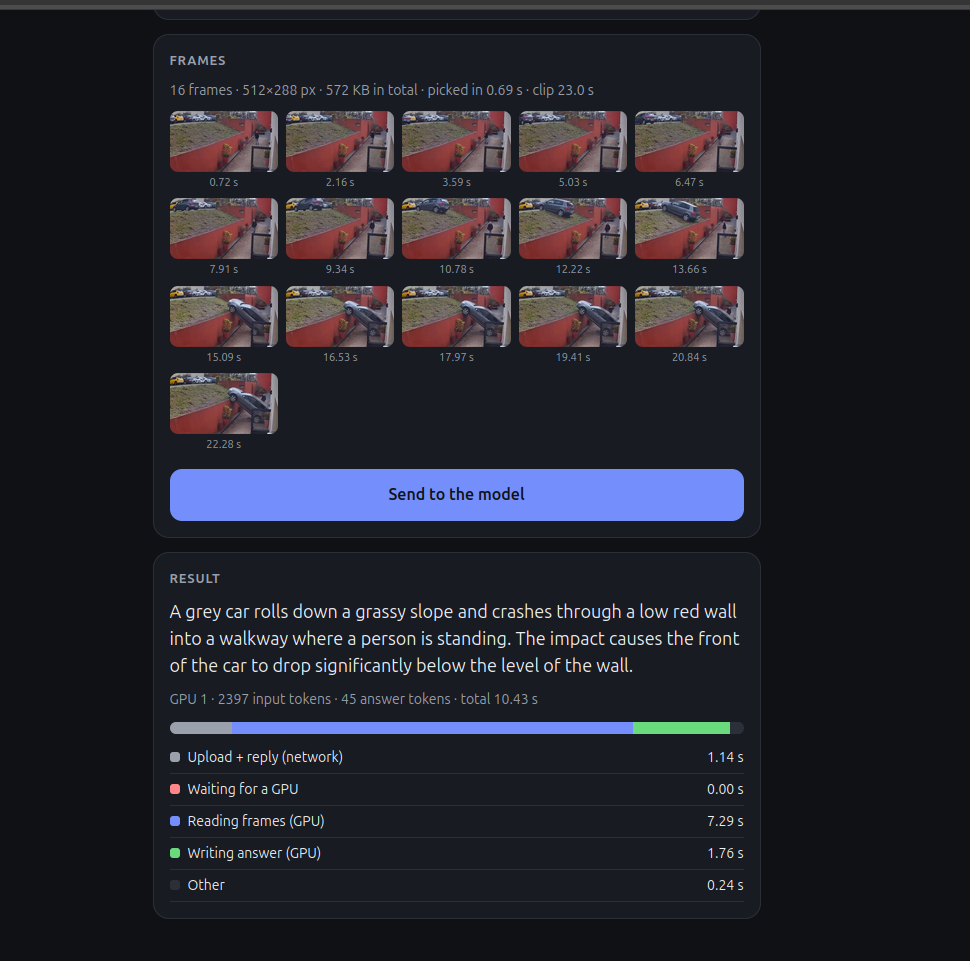

## 20. Results: Step 9, the phone page (clip mode), tested with clip01 (23 s, car crash)

**What we built**
1. 9.1: page served at `/` + Cloudflare quick tunnel (public https address -> port 8000 on Kaggle).
2. 9.2: the page picks N frames **in the browser**: hidden `<video>`, jump to (k + 0.5) x length / N,
   draw on a `<canvas>` at 512 px, save as JPEG. Page split into `index.html`, `static/style.css`, `static/app.js`.
3. 9.3: "Send to the model" -> `POST /analyze_clip` (429 "busy" instead of dropping) -> answer + time bar.
   New questions: one for 1 frame, one for several, no durations.

**Results (clip01, 512x288 frames, laptop browser)**

| Frames | Upload | Picked in | Input tokens | Network | Reading | Writing | Total | Answer |
|---|---|---|---|---|---|---|---|---|
| 1 (11.5 s)  | 35 KB  | 0.05 s | 193   | 0.37 s | 0.61 s | 2.01 s | 3.15 s  | car **"parked"** on the slope (wrong: it is rolling) |
| 8           | 286 KB | 0.35 s | 1,228 | 0.88 s | 4.10 s | 1.35 s | 6.53 s  | rolls down the slope, crashes through the red wall (correct) |
| 16          | 572 KB | 0.69 s | 2,397 | 1.14 s | 7.29 s | 1.76 s | 10.43 s | same story + "the front of the car drops below the wall" |

**Findings**
1. **Time context changes the answer.** 1 frame: "parked" (wrong). 8 and 16 frames: the crash is described correctly.
   This is the main point of the demo.
2. **8 frames are enough for this story; 16 add a detail** (the car's front dropping) for +3.9 s (10.43 - 6.53).
3. **Frames are cheap to send:** the clip is 3.5 MB, the 16 frames 572 KB (~6x less), the 8 frames 286 KB (~12x less).
   Picking them in the browser took under 0.7 s.
4. **Each 512x288 frame still costs ~146 tokens:** (2,397 - 1,228) / 8 = 146. Question text: 193 - 146 = 47 tokens.
5. **Reading is the biggest part** (63% of the total with 8 frames, 70% with 16),
   about 0.4 s per extra frame here ((7.29 - 4.10) / 8).
6. **The time bar adds up exactly**, e.g. 16 frames: 1.14 + 0 + 7.29 + 1.76 + 0.24 = 10.43 s.
7. **For live mode:** 16 frames take ~10.4 s including network, which fits a GPU's 12 s turn with only ~1.6 s margin.
   8 frames (6.5 s) leave a comfortable margin, so 8 is the safer default for live mode.

## 21. Results: Step 10, phone test (Android phone, Brave browser, through the tunnel)

Clip: 6.2 s, recorded on the phone in portrait. 8 frames, 288x512 px, 170 KB.

| Part | Time |
|---|---|
| Picking frames on the phone | 5.34 s (laptop: 0.35 s) |
| Upload + reply (network) | 0.78 s |
| Waiting for a GPU | 0.00 s |
| Reading frames (GPU 0) | 4.52 s |
| Writing answer (67 tokens) | 3.40 s |
| Other | 0.15 s |
| **Total after tapping Send** | **8.85 s** |

Answer: "A hand holds a small glass bowl … the hand then moves the bowl out of view, revealing a notebook …,
a calculator, and a pair of black headphones … Finally, the hand reaches in to pick up the headphones."

**Findings**
1. **The full chain works on a real phone**, and portrait video comes out upright (288x512 = same 1,228 tokens).
2. **Picking frames from a recorded clip is ~15x slower on the phone** (5.34 s vs 0.35 s): every jump in a
   high-resolution phone video is slow to decode. Live mode avoids this: it copies the current camera picture, no jumps.
3. **The model confuses camera movement with object movement** ("moves the bowl out of view" — the camera turned).
   For the demo: put the phone on a stand, like a real fixed surveillance camera.
4. **Long answers cost time:** 67 tokens took 3.40 s (~51 ms each, 38% of the total).
   For live mode: ask for one short sentence and lower `num_predict`.

## 22. Step 11: live mode

### 11.1 A separate page `/live` with the live camera
`getUserMedia` asks the browser for a live camera stream (permission prompt; only on https pages, which the tunnel gives us).
The stream is shown in a `<video>`. Live mode copies the current picture from it — no slow jumping in a file.
The clip page `/` stays unchanged, as the backup.

In [43]:
@app.get("/live")
def live_page():
    return FileResponse("/kaggle/working/live.html")

In [44]:
%%writefile -a /kaggle/working/static/style.css

/* new (11.1): live camera and links */
#camera { display: block; width: 100%; max-height: 60vh; object-fit: contain; border-radius: 12px; background: #000; }
a { color: var(--accent); text-decoration: none; }

Appending to /kaggle/working/static/style.css


In [45]:
%%writefile /kaggle/working/live.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Mode</title>
  <link rel="stylesheet" href="static/style.css?v=3">
</head>
<body>
<main>
  <header>
    <div>
      <h1>Live mode</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 · a new answer every 6 s · <a href="./">clip mode</a></p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Camera</h2>
    <video id="camera" muted playsinline autoplay></video>
    <p class="muted" id="cam-info">Camera off.</p>
    <p></p>
    <div class="row">
      <button class="btn" id="start">Start camera</button>
      <button class="btn secondary" id="stop" disabled>Stop</button>
    </div>
  </section>
</main>
<script src="static/live.js?v=1"></script>
</body>
</html>

Writing /kaggle/working/live.html


In [46]:
%%writefile /kaggle/working/static/live.js
const $ = (id) => document.getElementById(id);
let stream = null;                      // the live camera stream (null = camera off)

// --- Status pill (same as on the clip page) ---
async function checkServer() {
  try {
    const data = await (await fetch("hello?name=live")).json();
    $("status").className = "pill ok";
    $("status-text").textContent = `connected · ${data.gpus.length} GPUs`;
  } catch (error) {
    $("status").className = "pill err";
    $("status-text").textContent = "offline";
  }
}

// --- Start the camera ---
async function startCamera() {
  try {
    stream = await navigator.mediaDevices.getUserMedia({
      video: { facingMode: "environment", width: { ideal: 1280 }, height: { ideal: 720 } },
      audio: false,
    });
    const video = $("camera");
    video.srcObject = stream;           // show the live stream in the <video>
    await video.play();
    $("cam-info").textContent = `Camera on · ${video.videoWidth}×${video.videoHeight} px`;
    $("start").disabled = true;
    $("stop").disabled = false;
  } catch (error) {
    $("cam-info").textContent = "Camera error: " + error.message;
  }
}

// --- Stop the camera ---
function stopCamera() {
  if (stream) stream.getTracks().forEach((track) => track.stop());   // switches the camera light off
  stream = null;
  $("camera").srcObject = null;
  $("cam-info").textContent = "Camera off.";
  $("start").disabled = false;
  $("stop").disabled = true;
}

$("start").addEventListener("click", startCamera);
$("stop").addEventListener("click", stopCamera);
checkServer();

Writing /kaggle/working/static/live.js


### 11.2 Collect frames, send a segment every 6 s
Every 0.75 s the page copies the current camera picture (512 px JPEG). After 8 frames it sends them to
`/analyze_frames` **without waiting** and starts the next segment at once (pipeline).
At most 2 segments on their way (one per GPU); otherwise the new segment is skipped before uploading.
Delay of each answer: answer time - last frame time (shortest) to answer time - first frame time (longest).

In [47]:
%%writefile -a /kaggle/working/static/style.css

/* new (11.2): keep the pill on one line; list of live results */
.pill { white-space: nowrap; flex-shrink: 0; }
header > div { min-width: 0; margin-right: 10px; }
#log { list-style: none; padding: 0; margin: 0; font-size: 14px; }
#log li { padding: 8px 0; border-bottom: 1px solid var(--line); }

Appending to /kaggle/working/static/style.css


In [48]:
%%writefile /kaggle/working/live.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Mode</title>
  <link rel="stylesheet" href="static/style.css?v=4">
</head>
<body>
<main>
  <header>
    <div>
      <h1>Live mode</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 · <a href="./">clip mode</a></p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Camera</h2>
    <video id="camera" muted playsinline autoplay></video>
    <p class="muted" id="cam-info">Camera off.</p>
    <p class="muted" id="counters"></p>
    <p></p>
    <div class="row">
      <button class="btn" id="start">Start live</button>
      <button class="btn secondary" id="stop" disabled>Stop</button>
    </div>
  </section>

  <section class="card">
    <h2>What the model sees (newest first)</h2>
    <ol id="log"></ol>
  </section>
</main>
<script src="static/live.js?v=2"></script>
</body>
</html>

Overwriting /kaggle/working/live.html


In [49]:
%%writefile /kaggle/working/static/live.js
const $ = (id) => document.getElementById(id);

const N_FRAMES = 8;                       // frames per segment
const WINDOW_S = 6;                       // seconds per segment
const GAP_S = WINDOW_S / N_FRAMES;        // 6 / 8 = 0.75 s between frames
const MAX_SIDE = 512;                     // longest side of each frame, in pixels
const MAX_ON_THE_WAY = 2;                 // at most 2 segments waiting for an answer (one per GPU)

let stream = null;                        // live camera stream
let timer = null;                         // the 0.75 s clock
let current = [];                         // frames of the segment being collected
let counts = { sent: 0, answered: 0, skipped: 0, dropped: 0 };
let onTheWay = 0;                         // segments sent but not answered yet
let segmentNo = 0;
const canvas = document.createElement("canvas");

// --- Status pill ---
async function checkServer() {
  try {
    const data = await (await fetch("hello?name=live")).json();
    $("status").className = "pill ok";
    $("status-text").textContent = `connected · ${data.gpus.length} GPUs`;
  } catch (error) {
    $("status").className = "pill err";
    $("status-text").textContent = "offline";
  }
}

function log(text) {                      // add a line at the TOP of the list
  const li = document.createElement("li");
  li.textContent = text;
  $("log").prepend(li);
}

function showCounters() {
  $("counters").textContent = `segments sent ${counts.sent} · answered ${counts.answered} · ` +
    `skipped on phone ${counts.skipped} · dropped by server ${counts.dropped} · on the way ${onTheWay}`;
}

// --- Copy the current camera picture into a JPEG ---
function grabFrame() {
  const video = $("camera");
  const scale = Math.min(1, MAX_SIDE / Math.max(video.videoWidth, video.videoHeight));
  canvas.width = Math.round(video.videoWidth * scale);
  canvas.height = Math.round(video.videoHeight * scale);
  canvas.getContext("2d").drawImage(video, 0, 0, canvas.width, canvas.height);
  return new Promise((resolve) => canvas.toBlob(resolve, "image/jpeg", 0.85));
}

// --- Called every 0.75 s ---
async function tick() {
  const blob = await grabFrame();
  current.push({ blob, at: performance.now() });          // remember WHEN it was taken
  if (current.length === N_FRAMES) {
    const frames = current;
    current = [];                                          // start the next segment right away
    segmentNo += 1;
    sendSegment(segmentNo, frames);                        // no await: do not wait for the answer
  }
}

// --- Send one segment and show its answer when it arrives ---
async function sendSegment(no, frames) {
  if (onTheWay >= MAX_ON_THE_WAY) {                        // phone-side limit
    counts.skipped += 1;
    log(`#${no} skipped on the phone (2 segments still on their way)`);
    showCounters();
    return;
  }
  onTheWay += 1;
  counts.sent += 1;
  showCounters();

  const form = new FormData();
  frames.forEach((f, k) => form.append("frames", f.blob, `frame${k}.jpg`));
  form.append("gap", GAP_S.toString());
  const sentAt = performance.now();

  try {
    const reply = await fetch("analyze_frames", { method: "POST", body: form });
    const data = await reply.json();
    const now = performance.now();
    if (!reply.ok) throw new Error(data.error || `status ${reply.status}`);
    if (data.dropped) {
      counts.dropped += 1;
      log(`#${no} dropped by the server (a newer segment replaced it)`);
    } else {
      counts.answered += 1;
      const shortest = (now - frames[frames.length - 1].at) / 1000;   // since the last frame
      const longest = (now - frames[0].at) / 1000;                     // since the first frame
      log(`#${no} · GPU ${data.gpu} · round trip ${((now - sentAt) / 1000).toFixed(1)} s · ` +
          `delay ${shortest.toFixed(1)}–${longest.toFixed(1)} s · ${data.answer}`);
    }
  } catch (error) {
    log(`#${no} error: ${error.message}`);
  }
  onTheWay -= 1;
  showCounters();
}

// --- Start: camera on, then the 0.75 s clock ---
async function startLive() {
  try {
    stream = await navigator.mediaDevices.getUserMedia({
      video: { facingMode: "environment", width: { ideal: 1280 }, height: { ideal: 720 } },
      audio: false,
    });
    const video = $("camera");
    video.srcObject = stream;
    await video.play();
    $("cam-info").textContent =
      `Camera on · ${video.videoWidth}×${video.videoHeight} px · 1 frame every ${GAP_S} s · ` +
      `${N_FRAMES} frames per segment`;
    current = [];
    timer = setInterval(tick, GAP_S * 1000);              // run tick() every 750 ms
    $("start").disabled = true;
    $("stop").disabled = false;
    showCounters();
  } catch (error) {
    $("cam-info").textContent = "Camera error: " + error.message;
  }
}

// --- Stop: clock off, camera off (answers already on their way still arrive) ---
function stopLive() {
  clearInterval(timer);
  timer = null;
  current = [];                                            // an unfinished segment is thrown away
  if (stream) stream.getTracks().forEach((track) => track.stop());
  stream = null;
  $("camera").srcObject = null;
  $("cam-info").textContent = "Camera off.";
  $("start").disabled = false;
  $("stop").disabled = true;
}

$("start").addEventListener("click", startLive);
$("stop").addEventListener("click", stopLive);
checkServer();

Overwriting /kaggle/working/static/live.js


## 23. Results: Step 11.2, live mode on the phone (1 minute, phone carried by hand)

Settings: 8 frames per 6 s segment (1 frame every 0.75 s), 512 px, at most 2 segments on their way.

| Segment | GPU | Round trip | Delay range (last frame – first frame) |
|---|---|---|---|
| #1 | 0 | 8.4 s | 8.4 – 13.6 s |
| #2 | 1 | 6.7 s | 6.7 – 11.9 s |
| #3 | 0 | 7.8 s | 7.8 – 13.7 s |
| #4 | 1 | 6.4 s | 6.4 – 11.7 s |
| #5 | 0 | 6.9 s | 6.9 – 12.1 s |
| #6 | 1 | 6.3 s | 6.3 – 11.6 s |

**How to read the delay:** something in the last frame is described "round trip" seconds later; something in the first
frame 5.25 s more (7 gaps x 0.75 s). Example #6: 6.3 s and 11.6 s (11.6 - 6.3 = 5.3).

**Findings**
1. **The live pipeline works:** GPUs alternate 0,1,0,1,0,1, and the delay does not grow (#1: 8.4 s, #6: 6.3 s).
2. **Two GPUs are needed:** the average round trip, 42.5 / 6 = 7.1 s, is longer than the 6 s window. With one GPU,
   every segment would wait ~1.1 s longer than the one before. With two, each GPU is busy ~59% (7.1 / 12).
3. **The audience sees what happened 6 to 14 s ago** (measured; planned estimate was ~5 to 12 s).
4. **Round trip is longer than planned** (6.3–8.4 s vs ~5 s): long 2-sentence answers plus phone network time.
5. **The phone's clock slips a little:** #3 spanned 5.9 s instead of 5.25 s.
6. **Answers:** real scenes are understood (orange cat, tiled floor, person in white shirt and striped pants, movement).
   But many answers describe **camera movement** or **black frames**, because the phone was carried, not on a stand.
7. **The question shapes the answer:** "security camera" in the question makes the model assume one.
8. **No memory between segments:** every answer starts as if the video were new ("The video begins with…").

**Next improvements**
- Phone on a stand (fixed camera), as in real surveillance.
- Shorter answers for live mode (one short sentence, lower `num_predict`) for a faster round trip.
- Result cards with the 8 frames, the GPU and the delay (Step 11.3).

### 11.3 Result cards + short answers
Live mode asks for ONE sentence (max 20 words, max 40 tokens) to cut writing time, and says "fixed camera"
instead of "security camera". The value `short` travels: page -> /analyze_frames -> segment -> worker -> ask_gpu.
Each answer is shown as a card with its 8 frames, GPU, round trip and delay.

In [50]:
from typing import Annotated

QUESTION_SHORT = ("These {n} images are frames from one fixed camera, in time order, "
                  "about {gap:.2f} seconds apart. In ONE short sentence (at most 20 words), "
                  "say what happens. Plain text.")

def ask_gpu(gpu, frames, gap, short=False):
    """Ask the model on one GPU about a list of frames (JPEG bytes). Returns (answer, timing)."""
    if short:
        question, limit = QUESTION_SHORT.format(n=len(frames), gap=gap), 40
    elif len(frames) == 1:
        question, limit = QUESTION_ONE, 120
    else:
        question, limit = QUESTION_MANY.format(n=len(frames), gap=gap), 120
    start = time.time()
    r = clients[gpu].chat(
        model=MODEL,
        messages=[{"role": "user", "content": question, "images": frames}],
        think=False,
        options={"temperature": 0, "num_predict": limit},
    )
    timing = {
        "gpu":           gpu,
        "total_s":       round(time.time() - start, 2),
        "reading_s":     round(r["prompt_eval_duration"] / 1e9, 2),
        "writing_s":     round(r["eval_duration"] / 1e9, 2),
        "input_tokens":  r["prompt_eval_count"],
        "answer_tokens": r["eval_count"],
    }
    return r["message"]["content"], timing

In [52]:
def remove_route(path):
    """Remove an address from the server, so it can be defined again."""
    app.router.routes = [r for r in app.router.routes if getattr(r, "path", None) != path]

server_dispatcher = Dispatcher(gpus=[0, 1], on_result=on_done)   # built from the edited class
remove_route("/analyze_frames")

@app.post("/analyze_frames")
def analyze_frames(frames: Annotated[List[UploadFile], File()],
                   gap:    Annotated[float, Form()] = 0.75,
                   short:  Annotated[bool, Form()] = False):
    received = time.time()
    if not 1 <= len(frames) <= 16:
        return JSONResponse({"error": "send between 1 and 16 frames"}, status_code=400)

    segment = {"id": next(segment_ids),
               "frames": [f.file.read() for f in frames],
               "gap": gap,
               "short": short,
               "ready": received,
               "done": threading.Event()}
    server_dispatcher.submit(segment)

    if not segment["done"].wait(timeout=60):
        return JSONResponse({"error": "timed out"}, status_code=504)
    if segment.get("dropped"):
        return {"id": segment["id"], "dropped": True}
    return {"id":       segment["id"],
            "dropped":  False,
            "answer":   segment["answer"],
            "gpu":      segment["timing"]["gpu"],
            "waited_s": round(segment["started"] - received, 2),
            "timing":   segment["timing"],
            "server_s": round(time.time() - received, 2)}


# Quick check: 8 new frames (window 600-606 s, never sent before, so no cache), short and normal
files = make_segment(600.0)
for short in (True, False):
    r = requests.post("http://127.0.0.1:8000/analyze_frames", files=files,
                      data={"gap": 0.75, "short": short}).json()
    t = r["timing"]
    print(f"short={short}: {t['answer_tokens']} tokens, writing {t['writing_s']} s, total {t['total_s']} s\n   -> {r['answer']}")

short=True: 17 tokens, writing 0.65 s, total 4.65 s
   -> A blue rectangle moves from the left side of the screen to the right side.
short=False: 45 tokens, writing 1.44 s, total 5.0 s
   -> A blue rectangular object moves horizontally across the screen from left to right over a period of approximately 6 seconds. The time displayed in the top-left corner increases with each frame, indicating the passage of time during this movement.


In [53]:
%%writefile -a /kaggle/working/static/style.css

/* new (11.3): live result cards */
.seg { padding: 12px 0; border-top: 1px solid var(--line); }
.seg:first-child { border-top: 0; padding-top: 0; }
.seg .answer { font-size: 17px; margin: 0 0 8px; }
.seg:first-child .answer { font-weight: 600; }            /* the newest answer stands out */
.seg.note .answer { font-size: 14px; color: var(--muted); font-weight: 400; }
.meta { display: flex; flex-wrap: wrap; gap: 6px; font-size: 12px; color: var(--muted); }
.tag { padding: 2px 8px; border: 1px solid var(--line); border-radius: 999px; }
.tag.gpu0 { color: var(--accent); border-color: var(--accent); }
.tag.gpu1 { color: var(--ok); border-color: var(--ok); }
.strip { display: grid; grid-template-columns: repeat(8, 1fr); gap: 3px; margin-top: 8px; }
.strip img { display: block; width: 100%; border-radius: 4px; }
.switch { display: flex; align-items: center; gap: 8px; font-size: 14px; margin-top: 12px; }
.switch input { width: 20px; height: 20px; accent-color: var(--accent); }

Appending to /kaggle/working/static/style.css


In [54]:
%%writefile /kaggle/working/live.html
<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>VLM Live Mode</title>
  <link rel="stylesheet" href="static/style.css?v=5">
</head>
<body>
<main>
  <header>
    <div>
      <h1>Live mode</h1>
      <p class="sub">Qwen3.5 9B · 2× T4 · <a href="./">clip mode</a></p>
    </div>
    <span class="pill" id="status"><span class="dot"></span><span id="status-text">checking…</span></span>
  </header>

  <section class="card">
    <h2>Camera</h2>
    <video id="camera" muted playsinline autoplay></video>
    <p class="muted" id="cam-info">Camera off.</p>
    <p class="muted" id="counters"></p>
    <label class="switch"><input type="checkbox" id="short" checked> Short answers (one sentence, faster)</label>
    <p></p>
    <div class="row">
      <button class="btn" id="start">Start live</button>
      <button class="btn secondary" id="stop" disabled>Stop</button>
    </div>
  </section>

  <section class="card">
    <h2>What the model sees (newest first)</h2>
    <div id="feed"></div>
  </section>
</main>
<script src="static/live.js?v=3"></script>
</body>
</html>

Overwriting /kaggle/working/live.html


In [55]:
%%writefile /kaggle/working/static/live.js
const $ = (id) => document.getElementById(id);

const N_FRAMES = 8;                       // frames per segment
const WINDOW_S = 6;                       // seconds per segment
const GAP_S = WINDOW_S / N_FRAMES;        // 0.75 s between frames
const MAX_SIDE = 512;                     // longest side of each frame
const MAX_ON_THE_WAY = 2;                 // at most 2 segments waiting for an answer
const MAX_CARDS = 20;                     // keep only the newest 20 cards

let stream = null, timer = null, current = [], onTheWay = 0, segmentNo = 0;
let counts = { sent: 0, answered: 0, skipped: 0, dropped: 0 };
const canvas = document.createElement("canvas");

// --- Status pill ---
async function checkServer() {
  try {
    const data = await (await fetch("hello?name=live")).json();
    $("status").className = "pill ok";
    $("status-text").textContent = `connected · ${data.gpus.length} GPUs`;
  } catch (error) {
    $("status").className = "pill err";
    $("status-text").textContent = "offline";
  }
}

function showCounters() {
  $("counters").textContent = `sent ${counts.sent} · answered ${counts.answered} · ` +
    `skipped on phone ${counts.skipped} · dropped by server ${counts.dropped} · on the way ${onTheWay}`;
}

// --- Small helper: make an element with a class and text ---
function element(tag, className, text) {
  const el = document.createElement(tag);
  if (className) el.className = className;
  if (text !== undefined) el.textContent = text;
  return el;
}

// --- Put a card at the top of the feed; remove the oldest beyond MAX_CARDS ---
function addToFeed(card) {
  const feed = $("feed");
  feed.prepend(card);
  while (feed.children.length > MAX_CARDS) {
    const oldest = feed.lastElementChild;
    oldest.querySelectorAll("img").forEach((img) => URL.revokeObjectURL(img.src));   // free memory
    oldest.remove();
  }
}

function addNote(no, text) {                 // grey card: skipped, dropped, error
  const card = element("div", "seg note");
  card.append(element("p", "answer", `#${no} · ${text}`));
  addToFeed(card);
}

function addAnswer(no, frames, data, roundTrip, shortest, longest) {
  const card = element("div", "seg");
  card.append(element("p", "answer", data.answer));
  const meta = element("div", "meta");
  meta.append(
    element("span", "tag", `#${no}`),
    element("span", `tag gpu${data.gpu}`, `GPU ${data.gpu}`),
    element("span", "tag", `round trip ${roundTrip.toFixed(1)} s`),
    element("span", "tag", `delay ${shortest.toFixed(1)}–${longest.toFixed(1)} s`),
    element("span", "tag", `${data.timing.answer_tokens} tokens`),
  );
  const strip = element("div", "strip");
  for (const f of frames) {
    const img = element("img");
    img.src = URL.createObjectURL(f.blob);
    strip.append(img);
  }
  card.append(meta, strip);
  addToFeed(card);
}

// --- Copy the current camera picture into a JPEG ---
function grabFrame() {
  const video = $("camera");
  const scale = Math.min(1, MAX_SIDE / Math.max(video.videoWidth, video.videoHeight));
  canvas.width = Math.round(video.videoWidth * scale);
  canvas.height = Math.round(video.videoHeight * scale);
  canvas.getContext("2d").drawImage(video, 0, 0, canvas.width, canvas.height);
  return new Promise((resolve) => canvas.toBlob(resolve, "image/jpeg", 0.85));
}

// --- Called every 0.75 s ---
async function tick() {
  const blob = await grabFrame();
  current.push({ blob, at: performance.now() });
  if (current.length === N_FRAMES) {
    const frames = current;
    current = [];
    segmentNo += 1;
    sendSegment(segmentNo, frames);          // no await: keep collecting
  }
}

// --- Send one segment, show its card when the answer arrives ---
async function sendSegment(no, frames) {
  if (onTheWay >= MAX_ON_THE_WAY) {
    counts.skipped += 1;
    addNote(no, "skipped on the phone (2 segments still on their way)");
    showCounters();
    return;
  }
  onTheWay += 1;
  counts.sent += 1;
  showCounters();

  const form = new FormData();
  frames.forEach((f, k) => form.append("frames", f.blob, `frame${k}.jpg`));
  form.append("gap", GAP_S.toString());
  form.append("short", $("short").checked ? "true" : "false");
  const sentAt = performance.now();

  try {
    const reply = await fetch("analyze_frames", { method: "POST", body: form });
    const data = await reply.json();
    const now = performance.now();
    if (!reply.ok) throw new Error(data.error || `status ${reply.status}`);
    if (data.dropped) {
      counts.dropped += 1;
      addNote(no, "dropped by the server (a newer segment replaced it)");
    } else {
      counts.answered += 1;
      addAnswer(no, frames, data,
                (now - sentAt) / 1000,                              // round trip
                (now - frames[frames.length - 1].at) / 1000,        // delay since the last frame
                (now - frames[0].at) / 1000);                       // delay since the first frame
    }
  } catch (error) {
    addNote(no, "error: " + error.message);
  }
  onTheWay -= 1;
  showCounters();
}

// --- Start / stop ---
async function startLive() {
  try {
    stream = await navigator.mediaDevices.getUserMedia({
      video: { facingMode: "environment", width: { ideal: 1280 }, height: { ideal: 720 } },
      audio: false,
    });
    const video = $("camera");
    video.srcObject = stream;
    await video.play();
    $("cam-info").textContent = `Camera on · ${video.videoWidth}×${video.videoHeight} px · ` +
      `1 frame every ${GAP_S} s · ${N_FRAMES} frames per segment`;
    current = [];
    timer = setInterval(tick, GAP_S * 1000);
    $("start").disabled = true;
    $("stop").disabled = false;
    showCounters();
  } catch (error) {
    $("cam-info").textContent = "Camera error: " + error.message;
  }
}

function stopLive() {
  clearInterval(timer);
  timer = null;
  current = [];
  if (stream) stream.getTracks().forEach((track) => track.stop());
  stream = null;
  $("camera").srcObject = null;
  $("cam-info").textContent = "Camera off.";
  $("start").disabled = false;
  $("stop").disabled = true;
}

$("start").addEventListener("click", startLive);
$("stop").addEventListener("click", stopLive);
checkServer();

Overwriting /kaggle/working/static/live.js


## 24. Results: Step 11.3, short answers + result cards

**What we did**
- `ask_gpu(..., short=True)`: one sentence, max 20 words, max 40 tokens, "fixed camera" instead of "security camera".
- `short` travels page -> `/analyze_frames` -> segment -> worker -> `ask_gpu`.
  Old `/analyze_frames` removed with `remove_route` (the first matching route wins).
  `Annotated[bool, Form()] = False`, so the default is a real False also when `/analyze_clip` calls it directly.
- Result cards: answer, segment, GPU, round trip, delay, tokens, and the 8 frames the model saw. Newest 20 kept.

**Results (2 segments, phone held by hand, right after a restart)**

| Segment | GPU | Answer tokens | Round trip | Delay | Answer |
|---|---|---|---|---|---|
| #1 | 1 | 23 | 6.4 s | 6.4 – 11.7 s | laptop screen with code, orange cat on the desk |
| #2 | 0 | 22 | 8.5 s | 8.5 – 13.8 s | blurry laptop, then clearer views of the room |

**Findings**
1. Short answers work: 22–23 tokens instead of 40–67, so ~1–2 s less writing.
2. The round trip did not drop yet (6.4 / 8.5 s). Too few segments to say why; the card now also shows
   read / write time, so network = round trip - read - write - ~0.2 s.
3. The model reports blur honestly. A phone on a stand is needed for answers about events, not camera motion.
4. 0 skipped, 0 dropped.

## 25. Step 12: demo-day preparation

### 12.1 Save the page files
Kaggle deletes /kaggle/working when the session stops. We pack the page files into one zip,
download it, and push it to GitHub from the laptop (no GitHub token inside Kaggle).

In [56]:
import shutil

PACK = "/kaggle/working/my-demo"
os.makedirs(PACK, exist_ok=True)
for name in ("index.html", "live.html"):
    shutil.copy(f"/kaggle/working/{name}", f"{PACK}/{name}")
shutil.copytree("/kaggle/working/static", f"{PACK}/static", dirs_exist_ok=True)

shutil.make_archive(PACK, "zip", PACK)          # creates /kaggle/working/my-demo.zip
!ls -la {PACK} {PACK}/static
!ls -la /kaggle/working/my-demo.zip

/kaggle/working/my-demo:
total 20
drwxr-xr-x 3 root root 4096 Oct 24 09:44 .
drwxr-xr-x 5 root root 4096 Oct 24 09:44 ..
-rw-r--r-- 1 root root 2080 Oct 24 09:44 index.html
-rw-r--r-- 1 root root 1171 Oct 24 09:44 live.html
drwxr-xr-x 2 root root 4096 Oct 24 09:20 static

/kaggle/working/my-demo/static:
total 32
drwxr-xr-x 2 root root 4096 Oct 24 09:20 .
drwxr-xr-x 3 root root 4096 Oct 24 09:44 ..
-rw-r--r-- 1 root root 6424 Oct 24 09:20 app.js
-rw-r--r-- 1 root root 6179 Oct 24 09:22 live.js
-rw-r--r-- 1 root root 5037 Oct 24 09:21 style.css
-rw-r--r-- 1 root root 8451 Oct 24 09:44 /kaggle/working/my-demo.zip
